# Refracción sísmica (RF) — Línea L1 (cancha de fútbol): versión didáctica

Este cuaderno repite **el mismo procesamiento** de `L1_RF_analysis.ipynb`, pero abriendo las «cajas negras» de `utils/`. En cada etapa encontrarás:

1. **Concepto y matemática**: qué se hace y por qué, con las ecuaciones.
2. **Código**: o bien se *reimplementa a mano* el paso (y se comprueba con `assert` que da el mismo resultado que `utils/`), o bien se muestran los objetos intermedios.
3. **Qué manipular**: qué parámetro controla ese paso, qué pasa si lo subes o bajas, y cómo detectar que algo salió mal.

Las cifras que aparecen en el texto provienen de la ejecución incluida en este cuaderno con los parámetros por defecto; si cambias parámetros, las celdas de código recalculan todo, pero el texto no.

## Flujo completo

```
archivos SEG-2 ──► ShotGather ──► primeros arribos ──► curvas t–x ──► velocidades aparentes
 (.dat, 12 geófonos     (matriz         (picks, s)          │
  × 5 disparos)      muestras×trazas)                       ▼
                                          tomografía de tiempos de viaje (pyGIMLi)
                                          malla → modelo inicial → inversión regularizada
                                                          │
                                                          ▼
                              Vp(x, z)  ──►  Vp(z) en x = 27.5 m  ──┐
                                                                     ├─► ν, G, E ─► clasificación
                              Vs(z) del análisis MASW  ──────────────┘
```

## Convenciones

| Símbolo | Significado | Unidad |
|---|---|---|
| $x$ | posición a lo largo de la línea | m |
| $z$ | profundidad (positiva hacia abajo; en las mallas de pyGIMLi la coordenada vertical es $-z$) | m |
| $t$ | tiempo de viaje | s (en gráficos, ms) |
| $v$, $V_p$, $V_s$ | velocidad (onda P, onda S) | m/s |
| $s = 1/v$ | **lentitud** (variable natural de la tomografía) | s/m |
| $\Delta x$ | offset: distancia fuente–receptor | m |

## Índice

0. Configuración y parámetros
1. Fundamentos físicos: ¿qué es un primer arribo?
2. Carga de datos (SEG-2 y geometría)
3. Picado de primeros arribos
4. Curvas de tiempo de viaje y velocidades aparentes
5. Tomografía de tiempos de viaje (mallas, problema directo, problema inverso, QC)
6. Interpretación conjunta con MASW: $\nu$, $G$, $E$ y clasificación
7. Guía de manipulación: experimentos y diagnóstico
8. Limitaciones y cosas a vigilar

## 0. Configuración y parámetros

Todos los «mandos» del procesamiento están en la celda siguiente (son los mismos del cuaderno original). En la sección 7 hay una tabla que resume qué hace cada uno; aquí solo se agrupan por etapa:

* **Datos**: carpeta y corrección de la posición de una fuente.
* **Picado** (`PICK_*`): rango de velocidades admisible, ventana de ruido y umbral de detección.
* **Tomografía**: error asignado a cada pick, malla (`PARA_*`, `MESH_QUALITY`, `MAX_CELL_SIZE`), regularización (`LAM`, `CORR_LENGTHS`, `Z_WEIGHT`), modelo inicial (`V_TOP`, `V_BOTTOM`) y criterio de rechazo de picks (`MAX_RESIDUAL`).
* **Interpretación conjunta**: archivo de $V_s$, posición del perfil 1D, rango de profundidad y densidad.

Ejecuta el cuaderno desde la raíz del repositorio (donde está la carpeta `utils/`), con el kernel del entorno `seismic-l1`.

In [1]:
import logging
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pygimli as pg
import pygimli.physics.traveltime as tt

from utils import seg2_io, refraction, plotting, interpretation

pg.setLogLevel(logging.WARNING)          # menos mensajes de pyGIMLi
plt.rcParams.update({"figure.dpi": 110, "axes.grid": False})

# --- Datos ---------------------------------------------------------------
DATA_FOLDER = "L1/RF"
# La cabecera SEG-2 de este disparo dice 42.5 m pero el nombre del archivo dice 47.5 m;
# 47.5 m es coherente con los datos (se comprueba en la sección 2).
SOURCE_X_OVERRIDES = {"2026-10-08_RF_47.5m.dat": 47.5}

# --- Picado de primeros arribos (guiado por offset) ----------------------
PICK_V_MIN = 150.0          # m/s, velocidad aparente mínima admisible entre receptores vecinos
PICK_V_MAX = 1500.0         # m/s, velocidad aparente máxima admisible
PICK_NOISE_WINDOW = 0.010   # s, ventana inicial de cada traza usada para estimar el ruido
PICK_THRESHOLD = 3.0        # el pick se dispara cuando |amplitud| > umbral × RMS del ruido
PICK_OVERRIDES = {}         # correcciones manuales {(i_disparo, i_receptor): tiempo_s | np.nan}

# --- Tomografía 2D de tiempos de viaje (pyGIMLi) -------------------------
PICK_ERROR = 0.0035         # s, incertidumbre asignada a cada pick
PARA_DX = 0.33              # nodos extra entre sensores, RELATIVO al espaciado (1 = solo en sensores)
PARA_DEPTH = 12.0           # m, profundidad del modelo
MESH_QUALITY = 33.5         # ángulo mínimo de los triángulos (°); mantener <= 34
MAX_CELL_SIZE = 1.0         # m², área máxima de cada triángulo
PARA_BOUNDARY = 0.5         # margen lateral de la malla, en espaciados de sensor
LAM = 100.0                 # fuerza de la regularización
CORR_LENGTHS = [80.0, 1.0]  # longitudes de correlación [horizontal, vertical] (m); None → usa Z_WEIGHT
Z_WEIGHT = 1.0              # solo se usa si CORR_LENGTHS es None (< 1 favorece capas horizontales)
V_TOP, V_BOTTOM = 250.0, 1500.0   # m/s, gradiente del modelo inicial
MAX_RESIDUAL = 0.010        # s, picks con residuo mayor tras la inversión de QC se descartan

# --- Interpretación conjunta (Vp + Vs) -----------------------------------
MASW_VS_CSV = "L1/MASW_vs_profile.csv"
X_CENTER = 27.5             # m, posición del perfil 1D Vp(z)
Z_MIN_INTERP, Z_MAX_INTERP = 0.5, 10.0   # m
RHO = 1800.0                # kg/m³, densidad supuesta

## 1. Fundamentos físicos: ¿qué es un primer arribo?

### 1.1 Qué se mide

Un golpe de mazo genera ondas sísmicas. Los geófonos (12 en línea, cada 5 m) registran la velocidad vertical del suelo en función del tiempo. Para cada par fuente–receptor nos interesa **cuándo llega la primera energía**: el *primer arribo* (*first break*). Es lo único que usa la refracción; el resto del sismograma (ondas superficiales, reflexiones) se ignora aquí (las ondas superficiales se usan en el análisis MASW).

La velocidad de la onda P y de la onda S dependen del módulo de incompresibilidad $K$, del módulo de corte $G$ y de la densidad $\rho$:

$$V_p=\sqrt{\frac{K+\tfrac43 G}{\rho}},\qquad V_s=\sqrt{\frac{G}{\rho}}.$$

La refracción mide $V_p$; MASW mide $V_s$. Más adelante (sección 6) se combinan.

### 1.2 Ley de Snell y onda refractada crítica

Entre dos capas con velocidades $V_1<V_2$, la ley de Snell dice $\dfrac{\sin\theta_1}{V_1}=\dfrac{\sin\theta_2}{V_2}$. Cuando el ángulo de incidencia alcanza el **ángulo crítico**

$$\theta_c=\arcsin\!\left(\frac{V_1}{V_2}\right)$$

la onda transmitida viaja *rasante* por el tope de la capa rápida y, mientras lo hace, irradia energía de vuelta a la superficie (*onda frontal* o *head wave*).

### 1.3 Tiempos de viaje en un modelo de dos capas (espesor $z$)

* **Onda directa** (por la capa 1): $\;t_d(x)=\dfrac{x}{V_1}$.
* **Onda refractada**: $\;t_r(x)=\dfrac{x}{V_2}+t_i,\quad t_i=\dfrac{2z\sqrt{V_2^2-V_1^2}}{V_1V_2}$

  (el trayecto son dos tramos oblicuos de longitud $z/\cos\theta_c$ en la capa 1 más el tramo horizontal a velocidad $V_2$; $t_i$ es el *tiempo de intercepto* de la recta con el eje $t$).
* **Distancia de cruce** (donde ambas rectas se igualan, $t_d=t_r$):

$$x_c=\frac{t_i V_1V_2}{V_2-V_1}=2z\sqrt{\frac{V_2+V_1}{V_2-V_1}}.$$

* **Profundidad** a partir del intercepto: $\;z=\dfrac{t_i\,V_1V_2}{2\sqrt{V_2^2-V_1^2}}$.

El primer arribo es $t(x)=\min\{t_d,\,t_r\}$: para $x<x_c$ llega antes la directa, para $x>x_c$ la refractada.

En la celda siguiente se evalúan estas fórmulas con valores plausibles para un campo de césped: $V_1=250$ m/s (suelo blando), $V_2=1400$ m/s (suelo saturado), $z=2$ m.

ángulo crítico = 10.3°, intercepto = 15.7 ms, distancia de cruce = 4.79 m


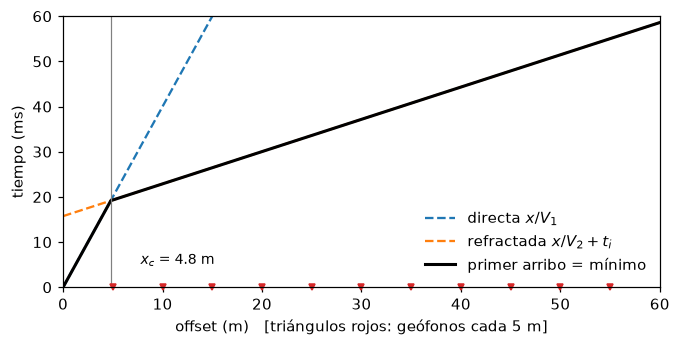

In [2]:
V1, V2, z = 250.0, 1400.0, 2.0                       # m/s, m/s, m
ti      = 2 * z * np.sqrt(V2**2 - V1**2) / (V1 * V2)  # tiempo de intercepto (s)
x_cross = 2 * z * np.sqrt((V2 + V1) / (V2 - V1))     # distancia de cruce (m)
theta_c = np.degrees(np.arcsin(V1 / V2))             # ángulo crítico (°)
print(f"ángulo crítico = {theta_c:.1f}°, intercepto = {ti*1e3:.1f} ms, distancia de cruce = {x_cross:.2f} m")

x = np.linspace(0, 60, 601)
t_dir, t_ref = x / V1, x / V2 + ti

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(x, t_dir * 1e3, "--", color="C0", label=r"directa $x/V_1$")
ax.plot(x, t_ref * 1e3, "--", color="C1", label=r"refractada $x/V_2+t_i$")
ax.plot(x, np.minimum(t_dir, t_ref) * 1e3, "k", lw=2, label="primer arribo = mínimo")
ax.axvline(x_cross, color="gray", lw=0.8)
ax.annotate(f"$x_c$ = {x_cross:.1f} m", (x_cross, 5), xytext=(x_cross + 3, 5), fontsize=9)
for xr in np.arange(5, 60, 5):                       # offsets de los geófonos (espaciado 5 m)
    ax.plot(xr, 0, "v", color="tab:red", ms=4, clip_on=False)
ax.set_xlim(0, 60); ax.set_ylim(0, 60)
ax.set_xlabel("offset (m)   [triángulos rojos: geófonos cada 5 m]"); ax.set_ylabel("tiempo (ms)")
ax.legend(frameon=False); plt.show()

**Consecuencia clave para este levantamiento.** La distancia de cruce ($\approx 4.8$ m) es del orden del espaciado entre geófonos (5 m). Los disparos *off-end* ($-5$ y $60$ m) tienen su receptor más cercano a 5 m, ya más allá del cruce: allí el primer arribo es la **onda refractada**. Solo en los disparos situados *entre* geófonos (12.5, 27.5, 47.5 m) hay receptores a 2.5 m, donde la onda directa aún puede ser la primera (en la sección 4 se verá una velocidad aparente de ≈ 200–270 m/s en esos offsets). Con a lo sumo uno o dos puntos de la rama directa por disparo, $V_1$ y el cruce no se pueden ajustar de forma fiable y el método clásico de intercepto (`refraction.two_layer_interpretation`) **no es aplicable**; se recurre a la tomografía.

Además, en suelos reales la velocidad no salta de golpe: suele *crecer de forma continua* con la profundidad (confinamiento, saturación). Los rayos entonces se curvan hacia arriba (*ondas de inmersión* o *diving waves*) y el modelo de dos capas es solo una aproximación. La tomografía no supone capas: estima $V_p(x,z)$ como un campo libre.

## 2. Carga de datos (SEG-2 y geometría)

`seg2_io.read_line` abre cada archivo `.dat` con ObsPy y construye un objeto `ShotGather` (un *registro de disparo*):

| Atributo | Significado |
|---|---|
| `data` | matriz `(n_muestras, n_receptores)`: cada columna es la traza de un geófono |
| `dt`, `fs = 1/dt` | intervalo y frecuencia de muestreo |
| `time` | eje temporal $t_k = k\,\Delta t$, $k = 0,\dots,N-1$ |
| `receiver_x`, `source_x` | posiciones (m), leídas de la cabecera SEG-2 |
| `offsets` | $\Delta x_i = |x_{\mathrm{rec},i}-x_{\mathrm{fuente}}|$ |

**Muestreo.** Con $\Delta t=0.125$ ms, $f_s = 8000$ Hz y la frecuencia de Nyquist es $f_s/2=4$ kHz; las ondas de interés (~20–100 Hz) están muy sobremuestreadas. La ventana total es $N\,\Delta t = 4096\times 0.125\,\text{ms}=0.512$ s. La resolución temporal de un pick es entonces ~0.1 ms, **mucho menor** que su incertidumbre real (varios ms, ver sección 3).

**Archivos apilados.** La carpeta contiene, por cada posición de fuente, un archivo apilado (p.ej. `..._RF_27.5m.dat`) y los golpes individuales (`..._shotN...`). Se leen solo los apilados (`exclude="_shot"`). Apilar $N$ golpes suma coherentemente la señal ($\propto N$) y solo en promedio el ruido aleatorio ($\propto\sqrt N$), mejorando la relación señal/ruido en un factor $\sqrt N$.

In [3]:
gathers = seg2_io.read_line(DATA_FOLDER, source_x_overrides=SOURCE_X_OVERRIDES)

g = gathers[2]                                           # disparo central (27.5 m)
print()
print("data.shape =", g.data.shape, "(n_muestras, n_receptores)")
print(f"dt = {g.dt*1e3:.3f} ms,  fs = {g.fs:.0f} Hz,  Nyquist = {g.fs/2:.0f} Hz,  duración = {g.n_samples*g.dt:.3f} s")
print("receptores x =", g.receiver_x)
print("offsets (disparo 27.5 m) =", g.offsets)

Read 5 shot gathers from L1/RF:
  2026-10-08_RF_-5m.dat: source at -5.0 m, 12 receivers (0.0-55.0 m), 4096 samples at 8000 Hz
  2026-10-08_RF_12.5m.dat: source at +12.5 m, 12 receivers (0.0-55.0 m), 4096 samples at 8000 Hz
  2026-10-08_RF_27.5m.dat: source at +27.5 m, 12 receivers (0.0-55.0 m), 4096 samples at 8000 Hz
  2026-10-08_RF_47.5m.dat: source at +47.5 m, 12 receivers (0.0-55.0 m), 4096 samples at 8000 Hz
  2026-10-08_RF_60m.dat: source at +60.0 m, 12 receivers (0.0-55.0 m), 4096 samples at 8000 Hz

data.shape = (4096, 12) (n_muestras, n_receptores)
dt = 0.125 ms,  fs = 8000 Hz,  Nyquist = 4000 Hz,  duración = 0.512 s
receptores x = [ 0.  5. 10. 15. 20. 25. 30. 35. 40. 45. 50. 55.]
offsets (disparo 27.5 m) = [27.5 22.5 17.5 12.5  7.5  2.5  2.5  7.5 12.5 17.5 22.5 27.5]


### 2.1 Geometría y primeras trazas

El perfil tiene 12 geófonos ($x=0,5,\dots,55$ m) y 5 posiciones de fuente. Como ninguna fuente coincide con un geófono, el número de sensores únicos que verá pyGIMLi es $12+5=17$ (se verifica más abajo: «17 sensors»). Dos fuentes quedan fuera del tendido ($-5$ m y $60$ m: disparos *off-end*), las otras tres quedan **entre** geófonos (12.5, 27.5 y 47.5 m).

Las trazas de la derecha muestran lo que se picará: a mayor offset la llegada es más tardía y mucho más débil.

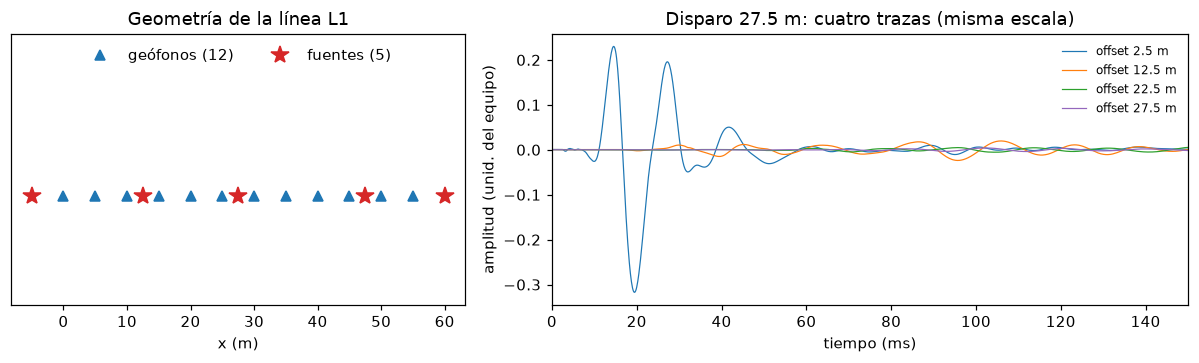

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.4), gridspec_kw={"width_ratios": [1, 1.4]})

ax1.plot(g.receiver_x, np.zeros(12), "^", color="C0", label="geófonos (12)")
ax1.plot([s.source_x for s in gathers], np.zeros(len(gathers)), "*", color="C3", ms=12, label="fuentes (5)")
ax1.set_yticks([]); ax1.set_xlabel("x (m)"); ax1.set_title("Geometría de la línea L1")
ax1.legend(frameon=False, loc="upper center", ncol=2); ax1.set_ylim(-1, 1.5)

order = np.argsort(g.offsets)
for k, c in zip([0, 4, 8, 11], ["C0", "C1", "C2", "C4"]):
    i = order[k]
    ax2.plot(g.time * 1e3, g.data[:, i] + 0.0, lw=0.8, color=c, label=f"offset {g.offsets[i]:.1f} m")
ax2.set_xlim(0, 150); ax2.set_xlabel("tiempo (ms)"); ax2.set_ylabel("amplitud (unid. del equipo)")
ax2.set_title("Disparo 27.5 m: cuatro trazas (misma escala)"); ax2.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

### 2.2 ¿Es 47.5 m o 42.5 m? Verificar la geometría con los datos

La cabecera de un archivo dice 42.5 m y el nombre del archivo 47.5 m. En vez de elegir a ciegas, se puede **usar la física**: la amplitud de la señal decae con la distancia a la fuente, de modo que las trazas de mayor amplitud deben ser las más cercanas a la fuente. Si la fuente estuviera en 47.5 m, los dos máximos deben caer en los geófonos de 45 y 50 m; si estuviera en 42.5 m, en 40 y 45 m.

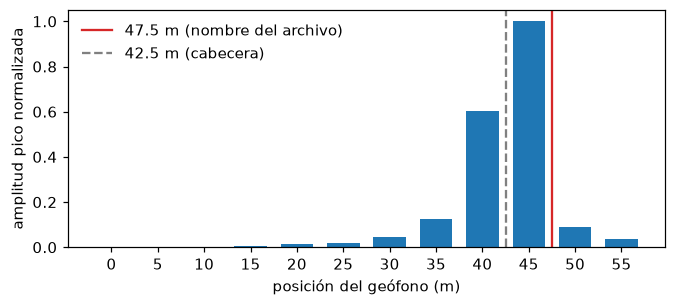

Geófonos con mayor amplitud: [45. 40.]


In [5]:
g47 = next(s for s in gathers if s.filename == "2026-10-08_RF_47.5m.dat")
win = g47.data[: int(0.12 / g47.dt)]                    # primeros 120 ms
peak = np.abs(win).max(axis=0)

fig, ax = plt.subplots(figsize=(7, 2.8))
ax.bar(g47.receiver_x, peak / peak.max(), width=3.5, color="C0")
ax.axvline(47.5, color="C3", lw=1.5, label="47.5 m (nombre del archivo)")
ax.axvline(42.5, color="gray", ls="--", lw=1.5, label="42.5 m (cabecera)")
ax.set_xlabel("posición del geófono (m)"); ax.set_ylabel("amplitud pico normalizada")
ax.set_xticks(g47.receiver_x); ax.legend(frameon=False); plt.show()
print("Geófonos con mayor amplitud:", g47.receiver_x[np.argsort(peak)[::-1][:2]])

Los dos máximos están en 45 y 50 m, es decir **la fuente está entre ambos (47.5 m)**. La amplitud decae además ~2 órdenes de magnitud a lo largo del tendido, lo que anticipa la dificultad de picar los offsets largos. En la sección 5.5 hay una segunda comprobación independiente (el ajuste χ² de la tomografía con 42.5 m es peor).

> **Regla práctica.** Cuando un metadato de campo sea dudoso, busca una observación de los *datos* que lo discrimine (aquí, amplitud; también sirve la simetría de tiempos de viaje).

## 3. Picado de primeros arribos

Todo lo que sigue depende de estos tiempos: **un pick malo contamina el tomograma**. Por eso conviene entender exactamente qué hace el algoritmo automático (`refraction.pick_first_breaks`) y cuándo falla.

### 3.1 El algoritmo, paso a paso

Los receptores se procesan **del más cercano al más lejano** a la fuente. Para cada traza $x_k$ ($k=0,\dots,N-1$) y con $N_0=\max(\lfloor T_{\text{ruido}}/\Delta t\rfloor,\,8)$ muestras de «ruido»:

1. **Quitar la componente continua** (desplazamiento DC): $\;\tilde x_k = x_k-\overline{x}_{0:N_0}$.
2. **Estimar el ruido** con la desviación estándar de la ventana previa a la llegada: $\;\sigma=\operatorname{std}(\tilde x_{0:N_0})$.
3. **Umbral de disparo**: $\;A_\text{trig}=\text{PICK\_THRESHOLD}\times\sigma$.
4. **Ventana de búsqueda guiada por offset.** Entre dos receptores vecinos con offsets $\Delta x_{i-1}$ y $\Delta x_i$, la pendiente $\Delta t/\Delta x$ de la curva de tiempos es $1/v_\text{ap}$, y $v_\text{ap}$ debe estar en $[v_\min, v_\max]$. Por tanto, dado el pick anterior $t_{i-1}$:

$$t_{i-1}+\frac{\Delta x_i-\Delta x_{i-1}}{v_\max}\;\le\; t_i\;\le\; t_{i-1}+\frac{\Delta x_i-\Delta x_{i-1}}{v_\min}.$$

   Para el primer receptor se usa $t_{i-1}=0$, $\Delta x_{i-1}=0$. Esto impide que una traza muy ruidosa «dispare» con ruido lejos del arribo real, y garantiza que los tiempos crecen con el offset.
5. **Disparo**: dentro de la ventana, se toma la primera muestra con $|\tilde x_k|>A_\text{trig}$. Si ninguna lo supera, se usa la muestra de mayor $|\tilde x_k|$ de la ventana.
6. **Refinamiento al inicio de la señal.** El umbral se supera *después* de que la señal empezó a crecer, así que se retrocede mientras la energía $\tilde x_k^{\,2}$ siga disminuyendo hacia atrás: el pick final es el **mínimo local de energía** previo al disparo, es decir, el comienzo del primer lóbulo.

### 3.2 Reimplementación didáctica

La función siguiente hace exactamente lo mismo pero **guarda los resultados intermedios** (σ, ventana, disparo, pick) para poder inspeccionarlos. Al final se comprueba que coincide con la de `utils/`.

In [ ]:
def pick_verbose(gather, v_min, v_max, noise_window, threshold):
    # Igual que refraction.pick_first_breaks, pero devuelve también los pasos intermedios.
    dt = gather.dt
    n_noise = max(int(noise_window / dt), 8)                      # N0
    picks = np.full(gather.n_receivers, np.nan)
    info = {}
    t_prev = offset_prev = None
    for i in np.argsort(gather.offsets):                          # del más cercano al más lejano
        trace = gather.data[:, i] - np.mean(gather.data[:n_noise, i])   # (1) quitar DC
        sigma = np.std(trace[:n_noise])                                  # (2) ruido
        offset = gather.offsets[i]

        if t_prev is None:                                       # (4) ventana permitida
            t_lo, t_hi = offset / v_max, offset / v_min
        else:
            t_lo = t_prev + (offset - offset_prev) / v_max
            t_hi = t_prev + (offset - offset_prev) / v_min
        j_lo = int(t_lo / dt)
        j_hi = min(int(t_hi / dt) + 1, gather.n_samples)

        window = np.abs(trace[j_lo:j_hi])
        above = np.nonzero(window > threshold * sigma)[0]        # (3)+(5) disparo
        j_trigger = j_lo + (above[0] if len(above) else int(np.argmax(window)))

        j = j_trigger                                            # (6) retroceder al mínimo de energía
        energy = trace ** 2
        while j > 0 and energy[j - 1] < energy[j]:
            j -= 1

        picks[i] = j * dt
        info[i] = dict(offset=offset, sigma=sigma, t_lo=t_lo, t_hi=t_hi,
                       j_trigger=j_trigger, pick=picks[i], trace=trace,
                       triggered=bool(len(above)))
        t_prev, offset_prev = picks[i], offset
    return picks, info


kw = dict(v_min=PICK_V_MIN, v_max=PICK_V_MAX, noise_window=PICK_NOISE_WINDOW, threshold=PICK_THRESHOLD)
gather = gathers[2]                                              # disparo de 27.5 m
my_picks, info = pick_verbose(gather, **kw)

# Comprobación: mismo resultado que la función de utils/
assert np.array_equal(my_picks, refraction.pick_first_breaks(gather, **kw))
print("OK: pick_verbose reproduce refraction.pick_first_breaks\n")

rows = []
for i in np.argsort(gather.offsets):
    r = info[i]
    rows.append({"receptor x (m)": gather.receiver_x[i], "offset (m)": r["offset"],
                 "σ ruido": r["sigma"], "ventana (ms)": f"{r['t_lo']*1e3:.1f} – {r['t_hi']*1e3:.1f}",
                 "disparo (ms)": r["j_trigger"] * gather.dt * 1e3, "pick final (ms)": r["pick"] * 1e3,
                 "¿superó umbral?": r["triggered"]})
pd.DataFrame(rows).round({"σ ruido": 5, "disparo (ms)": 2, "pick final (ms)": 2})

OK: pick_verbose reproduce refraction.pick_first_breaks



,receptor x (m),offset (m),σ ruido,ventana (ms),disparo (ms),pick final (ms),¿superó umbral?
0,30.0,2.5,0.00767,1.7 – 16.7,11.50,11.00,True
1,25.0,2.5,0.00618,11.0 – 11.0,11.00,9.88,True
2,35.0,7.5,0.00004,13.2 – 43.2,13.12,12.12,True
3,20.0,7.5,0.00011,12.1 – 12.1,12.12,12.12,False
4,15.0,12.5,0.00003,15.5 – 45.5,15.38,15.12,True
5,40.0,12.5,0.00004,15.1 – 15.1,15.12,15.12,False
6,45.0,17.5,0.00014,18.5 – 48.5,20.00,19.25,True
7,10.0,17.5,0.00007,19.2 – 19.2,19.25,19.25,False
8,50.0,22.5,0.00014,22.6 – 52.6,22.75,20.50,True
9,5.0,22.5,0.00005,20.5 – 20.5,20.50,20.12,False


Cosas que se ven en la tabla:

* El **pick final es ≤ al disparo**: el retroceso del paso 6 lo lleva al inicio real de la señal.
* La **ventana permitida** para un receptor nuevo mide $\Delta x\,(1/v_\min-1/v_\max)$: por ejemplo, para un salto de 5 m con 150–1500 m/s son 30 ms. Cuanto más estrecho el rango $[v_\min,v_\max]$, más «guiado» está el picado, pero un rango erróneo puede excluir el arribo real.
* Los receptores **equidistantes** de la fuente (p.ej. 25 y 30 m para la fuente de 27.5 m) tienen el mismo offset; para el segundo, $\Delta x_i-\Delta x_{i-1}=0$ y la ventana colapsa a ~1 muestra. Consecuencia: el segundo receptor de cada par **hereda prácticamente el pick del primero** (ver 3.5). En la tabla, esos receptores suelen aparecer con «¿superó umbral? = False»: no se disparó nada, y el pick sale de la única muestra de la ventana.

### 3.3 Visualización: qué ve el algoritmo en cuatro trazas

En cada panel: la traza sin DC (gris), el umbral $\pm A_\text{trig}$ (rojo), la ventana permitida (naranja), la muestra de disparo (×) y el pick final (línea azul). Observa cómo la relación señal/ruido (SNR = pico/σ) **cae con el offset**.

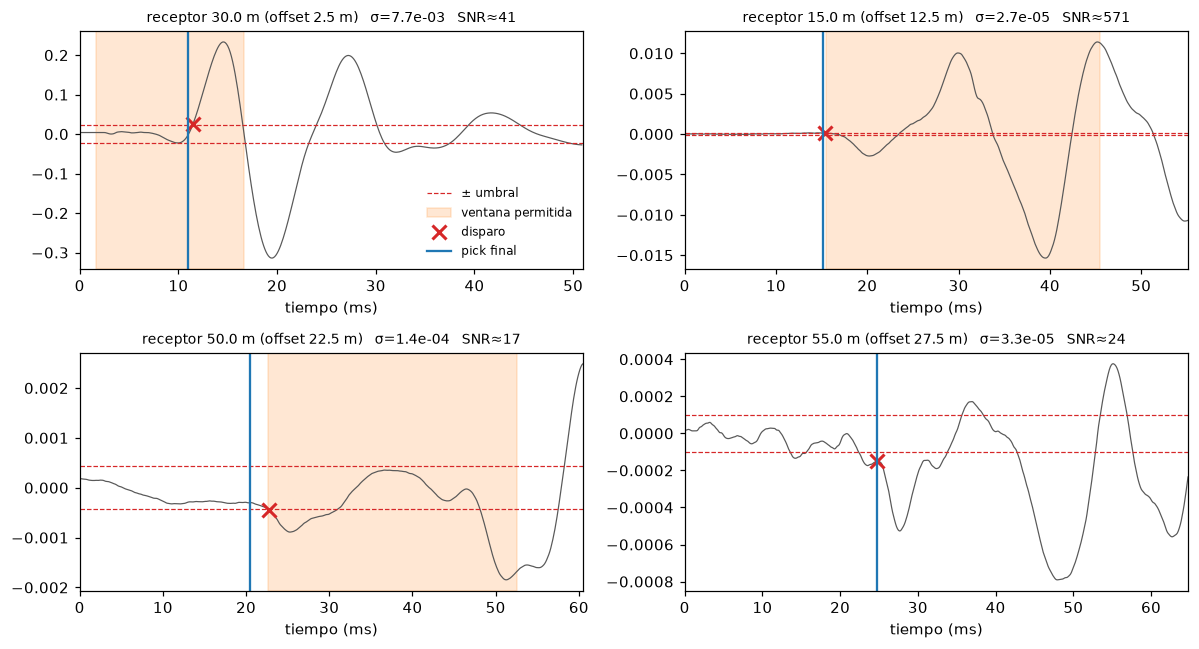

In [ ]:
order = np.argsort(gather.offsets)
fig, axes = plt.subplots(2, 2, figsize=(11, 6))
for ax, k in zip(axes.ravel(), [0, 4, 8, 11]):
    i = order[k]; r = info[i]; tr = r["trace"]; t_ms = gather.time * 1e3
    thr = PICK_THRESHOLD * r["sigma"]
    t_end = min(r["pick"] * 1e3 + 40, 250)
    sel = t_ms <= t_end
    ax.plot(t_ms[sel], tr[sel], color="0.35", lw=0.8)
    ax.axhline(thr, color="C3", lw=0.8, ls="--"); ax.axhline(-thr, color="C3", lw=0.8, ls="--", label=r"$\pm$ umbral")
    ax.axvspan(r["t_lo"] * 1e3, r["t_hi"] * 1e3, color="C1", alpha=0.18, label="ventana permitida")
    ax.plot(r["j_trigger"] * gather.dt * 1e3, tr[r["j_trigger"]], "x", color="C3", ms=9, mew=2, label="disparo")
    ax.axvline(r["pick"] * 1e3, color="C0", lw=1.5, label="pick final")
    snr = np.abs(tr[: int(t_end / 1e3 / gather.dt)]).max() / r["sigma"]
    ax.set_title(f"receptor {gather.receiver_x[i]:.1f} m (offset {r['offset']:.1f} m)   σ={r['sigma']:.1e}   SNR≈{snr:.0f}", fontsize=9)
    ax.set_xlim(0, t_end); ax.set_xlabel("tiempo (ms)")
axes[0, 0].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

**Cómo leer las cuatro trazas** (con el disparo de 27.5 m):

* *Panel superior izquierdo (2.5 m):* caso limpio. La señal es fuerte y el pick (azul) queda justo al inicio del primer lóbulo, un poco antes del disparo (×).
* *Panel superior derecho (12.5 m):* el pick se dispara sobre un **precursor diminuto** (~1 % del lóbulo principal, ver la escala) que sin embargo supera claramente el σ de un ruido previo muy bajo. Es una de las razones por las que el resultado depende de la ventana de ruido y del umbral (sección 3.7).
* *Panel inferior izquierdo (22.5 m):* el pick final (20.5 ms) queda **antes del inicio de la ventana permitida** (22.6 ms): el retroceso del paso 6 puede sacar el pick de la ventana. También es un caso de inicio gradual y ambiguo, de los menos fiables.
* *Panel inferior derecho (27.5 m):* el pick (24.75 ms) cae sobre una pequeña deflexión que supera el umbral antes del lóbulo principal (≈ 27 ms); con un umbral mayor el pick se iría 2–3 ms más tarde.

### 3.4 Incertidumbre del pick: ¿por qué `PICK_ERROR` ≈ 3.5 ms?

El muestreo (0.125 ms) no limita la precisión: la limita el **contenido en frecuencia** de la señal. Un lóbulo de frecuencia dominante $f_0$ tiene periodo $T_0=1/f_0$, y el inicio de la señal solo puede ubicarse con una fracción de $T_0$ (típicamente $T_0/10$ a $T_0/5$, según la SNR). Estimemos $f_0$ con la transformada de Fourier de los primeros 150 ms de cada disparo.

In [ ]:
rows = []
for s in gathers:
    n = int(0.15 / s.dt)
    spec = np.abs(np.fft.rfft(s.data[:n], n=4096, axis=0)).mean(axis=1)   # promedio sobre trazas
    f = np.fft.rfftfreq(4096, s.dt)
    f0 = f[1:][np.argmax(spec[1:])]
    rows.append({"fuente (m)": s.source_x, "f0 dominante (Hz)": round(f0, 1),
                 "periodo T0 (ms)": round(1e3 / f0, 1), "T0/10 – T0/5 (ms)": f"{100/f0:.1f} – {200/f0:.1f}"})
pd.DataFrame(rows)

,fuente (m),f0 dominante (Hz),periodo T0 (ms),T0/10 – T0/5 (ms)
0,-5.0,54.7,18.3,1.8 – 3.7
1,12.5,46.9,21.3,2.1 – 4.3
2,27.5,52.7,19.0,1.9 – 3.8
3,47.5,43.0,23.3,2.3 – 4.7
4,60.0,27.3,36.6,3.7 – 7.3


Con $f_0\approx 27$–$55$ Hz, $T_0\approx 18$–$37$ ms, y la incertidumbre esperable del pick, $T_0/10$–$T_0/5$, es de **2–7 ms**: un valor `PICK_ERROR = 3.5 ms` es físicamente razonable. Este número es crucial porque **pondera los datos en la inversión** (sección 5.4): si lo subes, la tomografía «tolera» más desajuste y produce modelos más suaves; si lo bajas, forzará un ajuste más estricto (posiblemente ajustando ruido).

### 3.5 Dos peculiaridades del picador que conviene conocer

**(a) Receptores equidistantes.** Como se explicó, el segundo receptor de cada par de igual offset hereda la ventana del primero. Verifica en los datos:

In [ ]:
picks = refraction.pick_line(gathers, overrides=PICK_OVERRIDES, v_min=PICK_V_MIN, v_max=PICK_V_MAX,
                             noise_window=PICK_NOISE_WINDOW, threshold=PICK_THRESHOLD)
rows = []
for s, p in zip(gathers, picks):
    off = np.round(s.offsets, 3)
    for o in np.unique(off):
        idx = np.where(off == o)[0]
        if len(idx) > 1:
            rows.append({"fuente (m)": s.source_x, "offset (m)": o,
                         "receptores (m)": ", ".join(f"{s.receiver_x[i]:.0f}" for i in idx),
                         "picks (ms)": ", ".join(f"{p[i]*1e3:.2f}" for i in idx)})
pd.DataFrame(rows)

,fuente (m),offset (m),receptores (m),picks (ms)
0,12.5,2.5,"10, 15","9.12, 9.12"
1,12.5,7.5,"5, 20","8.38, 8.38"
2,12.5,12.5,"0, 25","16.62, 16.62"
3,27.5,2.5,"25, 30","9.88, 11.00"
4,27.5,7.5,"20, 35","12.12, 12.12"
5,27.5,12.5,"15, 40","15.12, 15.12"
6,27.5,17.5,"10, 45","19.25, 19.25"
7,27.5,22.5,"5, 50","20.12, 20.50"
8,27.5,27.5,"0, 55","24.75, 24.75"
9,47.5,2.5,"45, 50","12.12, 13.38"


Los picks de cada pareja son idénticos o casi (la pequeña diferencia viene del retroceso del paso 6). Físicamente, si el subsuelo fuese lateralmente heterogéneo, los dos lados *podrían* diferir; el algoritmo actual **fuerza** esa simetría. Es un sesgo pequeño pero real; si te importa la asimetría lateral, revisa o corrige esos picks a mano con `PICK_OVERRIDES`.

**(b) La ventana de ruido puede contener señal.** `PICK_NOISE_WINDOW = 10 ms` supone que en los primeros 10 ms no hay llegada. Pero los offsets cortos llegan antes: cuántos picks caen dentro de esa ventana:

In [ ]:
all_picks = np.concatenate(picks)
n_early = int((all_picks < PICK_NOISE_WINDOW).sum())
print(f"{n_early} de {all_picks.size} picks caen antes de {PICK_NOISE_WINDOW*1e3:.0f} ms (dentro de la «ventana de ruido»).")
print("En esas trazas σ incluye parte de la señal → el umbral queda más alto y el disparo más tarde;")
print("el retroceso del paso 6 compensa parcialmente, pero esos picks son los menos fiables en términos de σ.")

7 de 60 picks caen antes de 10 ms (dentro de la «ventana de ruido»).
En esas trazas σ incluye parte de la señal → el umbral queda más alto y el disparo más tarde;
el retroceso del paso 6 compensa parcialmente, pero esos picks son los menos fiables en términos de σ.


### 3.6 Picks de toda la línea y control de calidad visual

`refraction.pick_line` aplica el algoritmo a todos los disparos y aplica `PICK_OVERRIDES` (correcciones manuales). La tabla muestra los picks en ms (filas: receptores; columnas: fuentes).

In [ ]:
refraction.picks_table(gathers, picks)

,source -5.0 m,source +12.5 m,source +27.5 m,source +47.5 m,source +60.0 m
0.0 m,6.62,16.62,24.75,59.50,52.62
5.0 m,13.12,8.38,20.12,52.62,49.38
10.0 m,17.12,9.12,19.25,47.62,46.38
15.0 m,19.38,9.12,15.12,36.38,43.38
20.0 m,22.88,8.38,12.12,33.38,32.75
25.0 m,25.75,16.62,9.88,28.38,28.12
30.0 m,29.00,18.62,11.00,23.62,25.00
35.0 m,31.88,19.88,12.12,20.38,22.88
40.0 m,38.88,33.50,15.12,18.50,21.12
45.0 m,46.38,36.00,19.25,12.12,15.00


**Regla de oro: revisa los picks sobre los sismogramas.** Los puntos (marcas azules) deben estar sobre el *inicio* del primer lóbulo en cada traza. Cada traza se normaliza a su propio máximo (por eso los offsets largos se ven tan «fuertes» como los cortos), así que la inspección visual evalúa la *forma*, no la amplitud relativa.

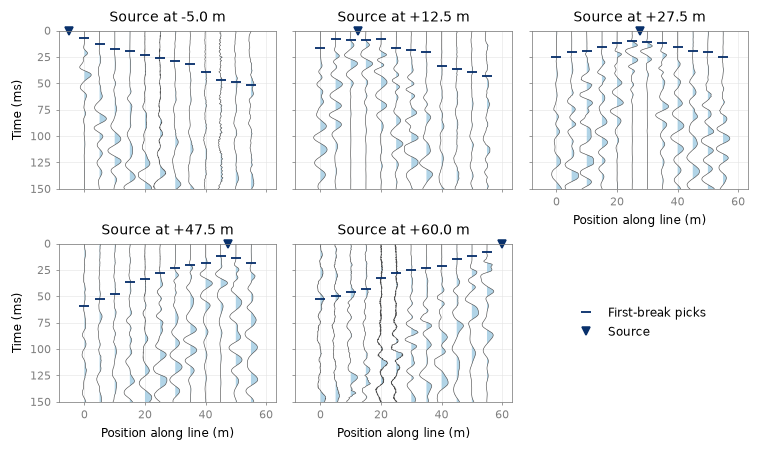

In [ ]:
plotting.plot_all_gathers(
    gathers, t_max=0.15, picks_per_shot=picks,
    ncols=3, width=7.0, panel_aspect=0.9, fontsize=8,
    scale=0.45, fill_color="#9ecae1", fill_alpha=0.8,
    line_color="#4d4d4d", line_width=0.4,
    pick_color="#08306b", pick_size=7, source_size=5,
    axis_color="#7f7f7f", label_color="k", grid_color="#e5e5e5", legend_loc="center",
)
plt.show()

### 3.7 Sensibilidad: el picado automático *no* es robusto a sus parámetros

Variemos `PICK_NOISE_WINDOW` y `PICK_THRESHOLD` y midamos cuánto cambian los picks respecto a la configuración base (promedio de $|\Delta t|$ sobre los 60 picks). El valor 0 en la configuración base es trivial; el resto muestra lo sensible que es el resultado.

In [ ]:
windows = [0.003, 0.005, 0.010, 0.020]
thresholds = [2.5, 3.0, 5.0, 8.0]
base = np.concatenate(picks)
table = pd.DataFrame(index=[f"ventana {w*1e3:.0f} ms" for w in windows],
                     columns=[f"umbral {t}" for t in thresholds], dtype=float)
for w in windows:
    for th in thresholds:
        p = np.concatenate(refraction.pick_line(gathers, v_min=PICK_V_MIN, v_max=PICK_V_MAX,
                                               noise_window=w, threshold=th))
        table.loc[f"ventana {w*1e3:.0f} ms", f"umbral {th}"] = np.nanmean(np.abs(p - base)) * 1e3
print("Cambio medio |Δt| respecto a la configuración base (ms):")
table.round(1)

Cambio medio |Δt| respecto a la configuración base (ms):


,umbral 2.5,umbral 3.0,umbral 5.0,umbral 8.0
ventana 3 ms,4.8,4.6,4.7,8.6
ventana 5 ms,3.0,2.7,7.7,15.2
ventana 10 ms,2.1,0.0,7.6,19.1
ventana 20 ms,6.9,13.5,23.7,33.5


Un cambio medio de varios ms (comparable o mayor que `PICK_ERROR`) significa que **la elección de estos parámetros afecta al resultado final**. La configuración actual (ventana 10 ms, umbral 3) se eligió con un barrido y revisión visual; si cambias los datos (otro sitio, otro equipo), repite ese barrido y revisa los sismogramas. Un umbral demasiado bajo dispara con ruido; demasiado alto, se pierden los arribos débiles de offsets largos o se pica en el lóbulo siguiente (tiempos tardíos).

> **Qué manipular**
> * `PICK_V_MIN`/`PICK_V_MAX`: ensanchar si los picks tocan los bordes de la ventana; estrechar para evitar saltos.
> * `PICK_THRESHOLD`: bajarlo si faltan arribos débiles; subirlo si hay picks en ruido previo.
> * `PICK_OVERRIDES = {(i_disparo, i_receptor): t_s}` para corregir a mano; usar `np.nan` para descartar un pick.

## 4. Curvas de tiempo de viaje y velocidades aparentes

### 4.1 Curvas $t$–$x$

Cada disparo da una curva de primeros arribos en función de la posición del receptor. El «valle» de cada curva está en la fuente (tiempo mínimo); la pendiente a cada lado es $\mathrm{d}t/\mathrm{d}x=1/v_\text{ap}$. Pendiente suave = material rápido; empinada = lento.

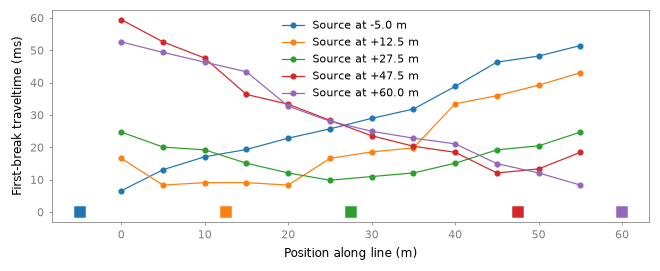

In [14]:
plotting.plot_traveltime_curves(
    gathers, picks, width=7.0, height=2.5, fontsize=8,
    line_width=0.8, marker="o", marker_size=3, source_marker="s", source_size=6,
    axis_color="#7f7f7f", label_color="k", grid_color="None", legend_loc="best", colors=None,
)
plt.show()

### 4.2 Velocidad aparente por regresión lineal

Para cada disparo y cada lado de la fuente se ajusta una recta por mínimos cuadrados $t=a+b\,\Delta x$ a los picks. Entonces

$$v_\text{ap}=\frac1b,\qquad \text{intercepto}=a.$$

`np.polyfit(offsets, picks, 1)` devuelve $(b,a)$ minimizando $\sum_i\bigl(t_i-a-b\,\Delta x_i\bigr)^2$.

**¿Por qué «aparente»?** Es la velocidad *a lo largo de la superficie*, no la del material. Si la capa refractora buza (inclinación $\delta$) y el ángulo crítico es $\theta_c$, hacia abajo y hacia arriba del buzamiento se miden velocidades distintas:

$$v_\text{ap,down}=\frac{V_1}{\sin(\theta_c+\delta)},\qquad v_\text{ap,up}=\frac{V_1}{\sin(\theta_c-\delta)}.$$

Diferencias grandes entre lados/disparos indican buzamiento o heterogeneidad lateral. Con velocidad creciente en profundidad (curvatura), una recta única es solo un resumen de la pendiente media.

Reproduzcamos a mano el disparo de 27.5 m, lado derecho, y comparemos con la función de `utils/`:

In [15]:
gather, p = gathers[2], picks[2]
mask = (gather.receiver_x > gather.source_x) & ~np.isnan(p)
slope, intercept = np.polyfit(gather.offsets[mask], p[mask], 1)
print(f"a mano: v_ap = {1/slope:.1f} m/s, intercepto = {intercept*1e3:.2f} ms")

table_v = refraction.apparent_velocities(gathers, picks)
row = table_v[(table_v.source_x_m == 27.5) & (table_v.side == "right")].iloc[0]
assert np.isclose(row.v_apparent_m_s, 1/slope, atol=0.1)
print("OK: coincide con refraction.apparent_velocities\n")
table_v

a mano: v_ap = 1785.7 m/s, intercepto = 8.73 ms
OK: coincide con refraction.apparent_velocities



,source_x_m,side,n_picks,v_apparent_m_s,intercept_ms
0,-5.0,right,12,1251.9,3.27
1,12.5,left,3,1333.3,5.75
2,12.5,right,9,1062.9,3.78
3,27.5,left,6,1707.3,8.09
4,27.5,right,6,1785.7,8.73
5,47.5,left,10,976.6,7.65
6,60.0,left,12,1206.1,2.81


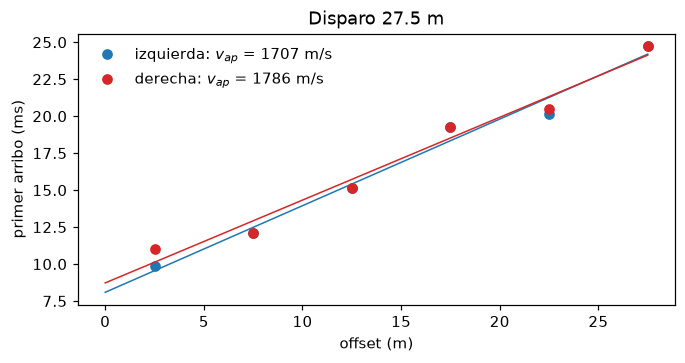

Velocidad aparente en el offset más corto de cada disparo (v = offset / t):
  fuente  -5.0 m: offset 5.0 m → 755 m/s
  fuente +12.5 m: offset 2.5 m → 274 m/s
  fuente +27.5 m: offset 2.5 m → 253 m/s
  fuente +47.5 m: offset 2.5 m → 206 m/s
  fuente +60.0 m: offset 5.0 m → 597 m/s


In [16]:
fig, ax = plt.subplots(figsize=(7, 3.2))
for side, c in [("izquierda", "C0"), ("derecha", "C3")]:
    m = (gather.receiver_x < gather.source_x if side == "izquierda" else gather.receiver_x > gather.source_x) & ~np.isnan(p)
    b, a = np.polyfit(gather.offsets[m], p[m], 1)
    ax.plot(gather.offsets[m], p[m] * 1e3, "o", color=c, label=f"{side}: $v_{{ap}}$ = {1/b:.0f} m/s")
    xx = np.linspace(0, gather.offsets[m].max(), 50)
    ax.plot(xx, (a + b * xx) * 1e3, "-", color=c, lw=1)
ax.set_xlabel("offset (m)"); ax.set_ylabel("primer arribo (ms)"); ax.set_title("Disparo 27.5 m")
ax.legend(frameon=False); plt.show()

near = [(s.source_x, s.offsets.min(), p_[np.argmin(s.offsets)]) for s, p_ in zip(gathers, picks)]
print("Velocidad aparente en el offset más corto de cada disparo (v = offset / t):")
for sx, off, t in near:
    print(f"  fuente {sx:+5.1f} m: offset {off:.1f} m → {off/t:.0f} m/s")

**Lectura.**

* En los disparos centrados (offset mínimo 2.5 m) la velocidad en el receptor más cercano es ≈ 200–270 m/s: es la **onda directa** por el suelo blando, $V_1$. En los disparos *off-end* (offset mínimo 5 m) ya es una llegada refractada o mixta (≈ 600–750 m/s, bastante mayor que la directa), como predice la sección 1.
* Los $v_\text{ap}$ de la tabla (≈ 1000–1800 m/s) son los de la rama refractada. Cerca del disparo central el $v_\text{ap}$ es el mayor y simétrico (~1700–1800 m/s), mientras que otros disparos dan 1000–1300 m/s: señal de **variación lateral/de profundidad**; no se puede interpretar sin un modelo, y de ahí la tomografía.
* El intercepto positivo (3–9 ms) es el tiempo «perdido» en la capa lenta superficial; es mayor cuando la capa lenta es más gruesa o más lenta.
* Con muy pocos puntos (p.ej. 3 picks en el lado izquierdo del disparo 12.5 m) la regresión es poco fiable: `apparent_velocities` exige al menos 3.

## 5. Tomografía de tiempos de viaje 2D

Con 5 m de espaciado el método clásico de capas planas no es aplicable (sección 1), así que se usa **tomografía**: en lugar de suponer capas, el subsuelo se divide en celdas y se busca la velocidad de cada una que mejor explique *todos* los tiempos picados a la vez.

### 5.0 Fundamento: principio de Fermat y la matriz de longitudes

El tiempo de viaje entre fuente $S$ y receptor $R$ es el **mínimo** sobre todos los caminos posibles (principio de Fermat):

$$t=\min_{\Gamma}\int_\Gamma s(\mathbf x)\,\mathrm d\ell,\qquad s=\frac1v\;\;(\text{lentitud}).$$

(Es equivalente a resolver la ecuación eikonal $|\nabla T|=s$.) Si el modelo se discretiza en $M$ celdas de lentitud constante $s_j$, y $L_{ij}$ es la **longitud del rayo $i$ dentro de la celda $j$**, entonces

$$\boxed{t_i=\sum_{j=1}^{M}L_{ij}\,s_j}\qquad\Longleftrightarrow\qquad \mathbf t=\mathbf L\,\mathbf s.$$

Se usa **lentitud** y no velocidad porque la relación es *lineal* en $s$. Pero el problema **no es lineal**: los rayos se curvan hacia las zonas rápidas, así que $\mathbf L$ depende de $\mathbf s$. De ahí que la inversión sea iterativa: *(1)* con el modelo actual se calculan rayos y tiempos (**problema directo**), *(2)* se compara con los picks, *(3)* se corrige el modelo (**problema inverso**), y se repite.

Hay además un problema de **cantidad de información**: aquí hay ≈ 60 tiempos y ≈ 1500 celdas. Sistema muy subdeterminado: infinitos modelos ajustan los datos, por lo que hace falta **regularización** (sección 5.4).

### 5.1 El contenedor de datos

`build_traveltime_data` convierte nuestros picks en un `DataContainerTT` de pyGIMLi: una lista de **sensores** (todas las posiciones únicas de fuentes y receptores, a $z=0$) y, por cada pick, el índice del sensor fuente `s`, el del receptor `g`, el tiempo `t` y su incertidumbre `err`. Los picks `NaN` o $\le 0$ se omiten.

In [17]:
data_tt = refraction.build_traveltime_data(gathers, picks, pick_error=PICK_ERROR)

sensors_x = np.array([data_tt.sensorPosition(i)[0] for i in range(data_tt.sensorCount())])
print("posiciones de sensores (m):", sensors_x)
print("(incluye -5, 47.5 y 60 m: fuentes fuera de los receptores 0–55 m)\n")

pd.DataFrame({
    "fuente x (m)": sensors_x[np.array(data_tt["s"], dtype=int)],
    "receptor x (m)": sensors_x[np.array(data_tt["g"], dtype=int)],
    "t (ms)": np.array(data_tt["t"]) * 1e3,
    "err (ms)": np.array(data_tt["err"]) * 1e3,
}).head(8)

Traveltime data: 17 sensors, 60 picks
posiciones de sensores (m): [-5.   0.   5.  10.  12.5 15.  20.  25.  27.5 30.  35.  40.  45.  47.5
 50.  55.  60. ]
(incluye -5, 47.5 y 60 m: fuentes fuera de los receptores 0–55 m)



,fuente x (m),receptor x (m),t (ms),err (ms)
0,-5.0,0.0,6.625,3.5
1,-5.0,5.0,13.125,3.5
2,-5.0,10.0,17.125,3.5
3,-5.0,15.0,19.375,3.5
4,-5.0,20.0,22.875,3.5
5,-5.0,25.0,25.750,3.5
6,-5.0,30.0,29.000,3.5
7,-5.0,35.0,31.875,3.5


### 5.2 La malla de inversión

Los *parámetros* de la inversión son los valores de lentitud en cada celda triangular de la malla: **cada celda es una incógnita**. La malla es un rectángulo bajo la superficie que cubre los sensores más un margen lateral (`PARA_BOUNDARY`).

| parámetro | significado | efecto de **aumentarlo** |
|---|---|---|
| `PARA_DX` | nodos adicionales entre sensores, relativo al espaciado (1 = solo en sensores; 0.33 = 2 nodos extra entre sensores) | **menor** valor → malla más fina (más celdas) |
| `PARA_DEPTH` | profundidad del modelo | más celdas profundas **sin cobertura de rayos** |
| `MESH_QUALITY` | ángulo mínimo de los triángulos (°); ≤ 34 | triángulos más uniformes, más celdas |
| `MAX_CELL_SIZE` | área máxima de celda (m²) | **menor** → más celdas |
| `PARA_BOUNDARY` | margen lateral, en espaciados de sensor | modelo se extiende más allá de los sensores |

Regla práctica: la profundidad que la refracción puede iluminar es del orden de 1/4–1/5 de la longitud del tendido (55 m → 11–14 m), de ahí `PARA_DEPTH = 12`.

**Compromiso:** celdas pequeñas permiten detalle, pero con tan pocos datos más celdas = más indeterminación (la regularización decide el resultado) y un cálculo más lento. Celdas mucho mayores que la longitud de onda del problema (~ metros) pierden resolución. Mira la malla:

Mesh: 1510 cells, 826 nodes (paraDX=0.33, depth=12.0 m, quality=33.5)


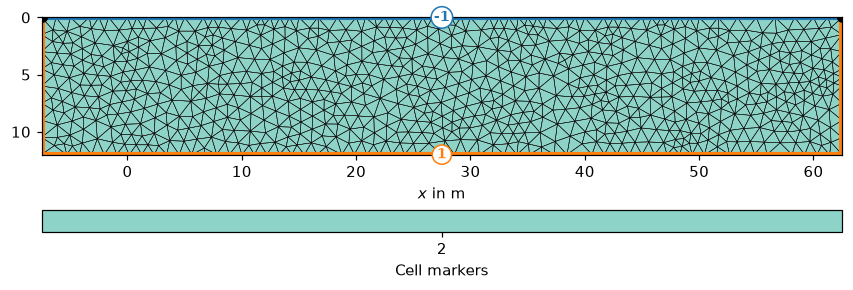

datos N = 60,  parámetros M = 1510 celdas  →  M/N ≈ 25 incógnitas por dato


In [18]:
mesh = refraction.create_mesh(
    data_tt, para_dx=PARA_DX, para_depth=PARA_DEPTH,
    quality=MESH_QUALITY, max_cell_size=MAX_CELL_SIZE, para_boundary=PARA_BOUNDARY,
)
ax, _ = pg.show(mesh, markers=True, showMesh=True)
ax.figure.set_size_inches(8, 3.2)
plt.show()

print(f"datos N = {data_tt.size()},  parámetros M = {mesh.cellCount()} celdas  →  M/N ≈ {mesh.cellCount()/data_tt.size():.0f} incógnitas por dato")

### 5.3 El problema directo: tiempos de viaje por Dijkstra

pyGIMLi calcula los tiempos con un **camino mínimo en un grafo** (algoritmo de Dijkstra): los nodos de la malla son vértices, y cada arista cuesta (longitud × lentitud de la celda). Limitación: los rayos solo pueden ir por aristas, es decir en un número finito de direcciones, y eso **sobrestima los tiempos** (camino en zig-zag). `secNodes` añade **nodos secundarios** en cada arista, lo que permite más direcciones y rayos más suaves, a costa de más cálculo. En la inversión se usa `secNodes=2`.

**Verificación.** Comparemos el cálculo numérico con soluciones analíticas:

* **Dos capas** ($V_1=300$, $V_2=1500$ m/s, interfaz a $z=3$ m): $t=\min\{x/V_1,\;x/V_2+t_i\}$.
* **Gradiente constante** $v(z)=v_0+gz$: $t=\dfrac{2}{g}\operatorname{arcsinh}\!\dfrac{g x}{2v_0}$ (solo offsets ≤ 20 m para que los rayos no salgan de la zona detallada).

Disparos desde $x=0$ y $x=30$ m con receptores cada 5 m. Se asigna a cada celda la velocidad del punto central.

In [19]:
xs = np.arange(0.0, 56.0, 5.0)
scheme = pg.DataContainer()
for xi in xs:
    scheme.createSensor([xi, 0.0])
s_idx, g_idx = zip(*[(a, b) for a in (0, 6) for b in range(len(xs)) if b != a])
scheme.resize(len(s_idx)); scheme.set("s", np.array(s_idx, float)); scheme.set("g", np.array(g_idx, float))
offs = np.abs(xs[list(g_idx)] - xs[list(s_idx)])

mgr_fwd = tt.TravelTimeManager(verbose=False)
mesh_fwd = mgr_fwd.createMesh(data=scheme, paraDX=PARA_DX, paraDepth=PARA_DEPTH, quality=MESH_QUALITY,
                              paraMaxCellSize=MAX_CELL_SIZE, paraBoundary=PARA_BOUNDARY)
cz = -np.array(pg.y(mesh_fwd.cellCenters()))            # profundidad de cada celda

V1, V2, z_int = 300.0, 1500.0, 3.0
t_i = 2 * z_int * np.sqrt(V2**2 - V1**2) / (V1 * V2)
cases = {
    "dos capas": (np.where(cz < z_int, V1, V2), np.minimum(offs / V1, offs / V2 + t_i), offs > 0),
    "gradiente (≤20 m)": (250.0 + 100.0 * cz, 2 / 100.0 * np.arcsinh(100.0 * offs / (2 * 250.0)), offs <= 20),
}
rows = []
for name, (vel, t_exact, use) in cases.items():
    for sn in [0, 1, 2, 5]:
        sim = mgr_fwd.simulate(slowness=1 / vel, scheme=scheme, mesh=mesh_fwd,
                               secNodes=sn, noiseLevel=0, noiseAbs=0)
        t_num = np.array(sim["t"])
        err = (t_num - t_exact)[use] * 1e3
        rows.append({"modelo": name, "secNodes": sn, "error máx |Δt| (ms)": np.abs(err).max(),
                     "error medio (ms)": err.mean()})
pd.DataFrame(rows).round(2)

,modelo,secNodes,error máx |Δt| (ms),error medio (ms)
0,dos capas,0,1.67,-0.06
1,dos capas,1,2.60,-0.92
2,dos capas,2,2.84,-1.15
3,dos capas,5,2.93,-1.26
4,gradiente (≤20 m),0,0.87,0.03
5,gradiente (≤20 m),1,0.83,-0.44
6,gradiente (≤20 m),2,0.85,-0.54
7,gradiente (≤20 m),5,1.02,-0.67


**Lectura.** El error del cálculo directo es de **≈ 1–3 ms**, comparable con `PICK_ERROR` (3.5 ms). Dos consecuencias:

1. Subir `secNodes` *no* reduce el error de forma monótona aquí: el error dominante no es el de las direcciones del grafo, sino la **discretización del propio modelo** (celdas de velocidad constante que aproximan una interfaz o un gradiente continuos). Un valor `secNodes=2` es un compromiso razonable.
2. Cualquier χ² menor que ~1 con `PICK_ERROR` ≈ 3 ms **no puede interpretarse literalmente**: la propia física numérica tiene un piso de error similar al de los picks.

### 5.4 El problema inverso

#### 5.4.1 Función objetivo

Con $\mathbf d$ los tiempos observados, $f(\mathbf m)$ el modelo directo, $\varepsilon_i$ la incertidumbre de cada dato (aquí `PICK_ERROR`), y $\mathbf m=\ln\mathbf s$ el modelo (pyGIMLi usa **logaritmo de la lentitud**, que garantiza $s>0$ y trata por igual cambios relativos):

$$\Phi(\mathbf m)=\underbrace{\sum_{i=1}^{N}\left(\frac{d_i-f_i(\mathbf m)}{\varepsilon_i}\right)^{2}}_{\text{desajuste de los datos}}+\;\lambda\,\underbrace{\|\mathbf C\,(\mathbf m-\mathbf m_\text{ref})\|^{2}}_{\text{regularización}}.$$

* El **desajuste** pondera cada dato por su incertidumbre.
* La **regularización** penaliza modelos «complicados». $\mathbf C$ define qué significa complicado (rugosidad, desviación del modelo de referencia).
* $\lambda$ es el *dial* entre ajustar los datos (λ pequeño) y obtener un modelo simple (λ grande).

#### 5.4.2 Paso de Gauss-Newton

Se linealiza $f(\mathbf m+\Delta\mathbf m)\approx f(\mathbf m)+\mathbf J\,\Delta\mathbf m$, con la **jacobiana** $J_{ij}=\partial f_i/\partial m_j$ (sensibilidad del dato $i$ a la celda $j$; para lentitud, $J_{ij}=L_{ij}$, y para $\ln s$ se multiplica por $s_j$). Minimizando $\Phi$ se obtiene

$$\bigl(\mathbf J^{T}\mathbf W^{T}\mathbf W\mathbf J+\lambda\,\mathbf C^{T}\mathbf C\bigr)\,\Delta\mathbf m=\mathbf J^{T}\mathbf W^{T}\mathbf W\,(\mathbf d-f(\mathbf m))-\lambda\,\mathbf C^{T}\mathbf C\,(\mathbf m-\mathbf m_\text{ref}),\qquad \mathbf W=\operatorname{diag}(1/\varepsilon_i)$$

y se actualiza $\mathbf m\leftarrow\mathbf m+\tau\,\Delta\mathbf m$, con un factor $\tau\in(0,1]$ de **búsqueda lineal** para garantizar que $\Phi$ baje.

#### 5.4.3 Criterio de parada y $\chi^2$

$$\chi^2=\frac1N\sum_i\left(\frac{d_i-f_i}{\varepsilon_i}\right)^2.$$

* $\chi^2=1$ significa que el residuo típico es igual a la incertidumbre asignada: ajustar mejor sería **ajustar ruido**; ajustar peor, no explicar los datos.
* pyGIMLi se detiene cuando $\chi^2\le1$, cuando $\Phi$ baja menos de 1 % entre iteraciones, o a las 20 iteraciones.
* Ojo: *el $\chi^2\approx1$ final no demuestra que el modelo sea correcto*. Si `PICK_ERROR` se eligió a partir del nivel de residuo (como aquí) y la inversión se detiene al llegar a $\chi^2\le1$, el valor es parcialmente circular. Lo que sí informa es **dónde** están los residuos grandes (sección 5.5).

#### 5.4.4 Ejemplo de juguete: ¿qué hace $\lambda$?

Para ver el efecto de $\lambda$ sin la complejidad 2D, hagamos un problema **lineal 1D tipo «checkshot»**: 40 celdas de 0.25 m (10 m de profundidad), 12 receptores a distintas profundidades, y rayos verticales, así que $t_i=\sum_j L_{ij}s_j$ con $L_{ij}$ = espesor de la celda $j$ por encima del receptor $i$. Se añade ruido de 0.2 ms y se regulariza con **primeras diferencias** ($\mathbf C$ penaliza saltos entre celdas vecinas). La solución es

$$\mathbf s_\lambda=\bigl(\mathbf L^{T}\mathbf W^{T}\mathbf W\mathbf L+\lambda\mathbf C^{T}\mathbf C\bigr)^{-1}\mathbf L^{T}\mathbf W^{T}\mathbf W\,\mathbf d.$$

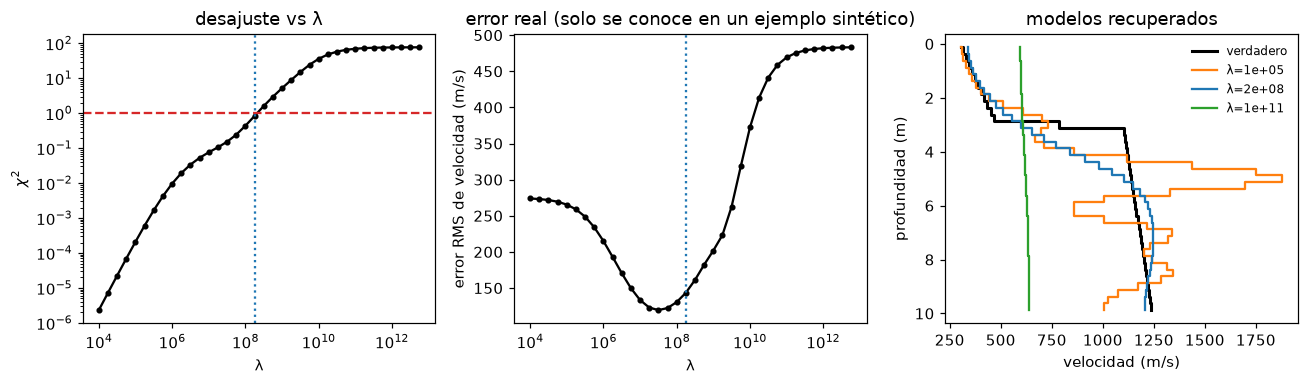

λ con χ² ≈ 1 (principio de discrepancia): 1.8e+08


In [20]:
rng = np.random.default_rng(1)
nz, dz, eps = 40, 0.25, 0.2e-3
zc = (np.arange(nz) + 0.5) * dz
v_true = np.where(zc < 3, 300 + 60 * zc, 1100 + 20 * (zc - 3))           # capa lenta sobre capa rápida
z_rec = np.linspace(0.75, 9.75, 12)
L = np.array([[min(max(zr - k * dz, 0.0), dz) for k in range(nz)] for zr in z_rec])   # longitudes L_ij
d_obs = L @ (1 / v_true) + rng.normal(0, eps, len(z_rec))
C = (np.eye(nz, k=1) - np.eye(nz))[:-1]                                   # primeras diferencias

def solve_toy(lam):
    A = (L / eps).T @ (L / eps) + lam * C.T @ C
    return np.linalg.solve(A, (L / eps).T @ (d_obs / eps))

lams = 10.0 ** np.arange(4, 13, 0.25)
chi2 = np.array([np.mean(((d_obs - L @ solve_toy(l)) / eps) ** 2) for l in lams])
err_v = np.array([np.sqrt(np.mean((1 / solve_toy(l) - v_true) ** 2)) for l in lams])
lam_star = lams[chi2 <= 1][-1]                                            # el mayor λ con χ² ≤ 1

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
axes[0].loglog(lams, chi2, "k-o", ms=3); axes[0].axhline(1, color="C3", ls="--")
axes[0].axvline(lam_star, color="C0", ls=":")
axes[0].set_xlabel("λ"); axes[0].set_ylabel(r"$\chi^2$"); axes[0].set_title("desajuste vs λ")
axes[1].semilogx(lams, err_v, "k-o", ms=3); axes[1].axvline(lam_star, color="C0", ls=":")
axes[1].set_xlabel("λ"); axes[1].set_ylabel("error RMS de velocidad (m/s)"); axes[1].set_title("error real (solo se conoce en un ejemplo sintético)")
axes[2].step(v_true, zc, "k", where="mid", lw=2, label="verdadero")
for lam, c in [(1e5, "C1"), (lam_star, "C0"), (1e11, "C2")]:
    axes[2].step(1 / solve_toy(lam), zc, c, where="mid", label=f"λ={lam:.0e}")
axes[2].invert_yaxis(); axes[2].set_xlabel("velocidad (m/s)"); axes[2].set_ylabel("profundidad (m)"); axes[2].legend(frameon=False, fontsize=8)
axes[2].set_title("modelos recuperados")
plt.tight_layout(); plt.show()
print(f"λ con χ² ≈ 1 (principio de discrepancia): {lam_star:.1e}")

**Qué enseña este ejemplo**

* λ **muy pequeño** (naranja): $\chi^2\ll1$, el modelo ajusta hasta el ruido (oscila: velocidades absurdas).
* λ **muy grande** (verde): $\chi^2\gg1$, el modelo se vuelve casi constante y no explica los datos.
* λ **con $\chi^2\approx1$** (azul): es el *principio de discrepancia*, y en este caso cae cerca del mínimo del error real. Es la lógica detrás de `stopAtChi1`.
* Los **valores absolutos de λ no son comparables** con `LAM = 100` de pyGIMLi: dependen de las unidades y de cómo se normaliza $\mathbf C$. Lo transferible es el *comportamiento*: subir `LAM` → modelo más suave y χ² más alto.
* La resolución se pierde con la profundidad y entre receptores: con datos tan escasos, los detalles más finos que ~ el espaciado de receptores no están constreñidos por los datos, sino por $\mathbf C$.

#### 5.4.5 La regularización geoestadística de este notebook

Con `CORR_LENGTHS=[80, 1]` no se penalizan diferencias finitas, sino una **covarianza exponencial** entre celdas (Jordi et al., 2018):

$$\mathrm{Cov}(\mathbf r_i,\mathbf r_j)=\exp\!\left(-\sqrt{\Bigl(\tfrac{\Delta x}{I_x}\Bigr)^{2}+\Bigl(\tfrac{\Delta z}{I_z}\Bigr)^{2}}\right),\qquad \text{penalización}\;\propto\;\mathbf m^{T}\,\mathrm{Cov}^{-1}\,\mathbf m.$$

Las **longitudes de correlación** $I_x, I_z$ son las distancias a las que dos celdas dejan de estar «acopladas». Con $I_x=80$ m $\gg I_z=1$ m el modelo se vuelve **laminado**: es casi lateralmente uniforme y varía en profundidad. **Es una suposición fuerte** y condiciona el resultado: si hubiera variaciones laterales reales (por ejemplo, una zanja), esta regularización tenderá a aplanarlas. Compara el acople entre celdas:

In [21]:
def cov(dx, dz_, Ix, Iz):
    return np.exp(-np.sqrt((dx / Ix) ** 2 + (dz_ / Iz) ** 2))

dists = [0.5, 1, 2, 5, 10, 20]
pd.DataFrame({
    "distancia (m)": dists,
    "horizontal, I=[80,1]": [cov(h, 0, 80, 1) for h in dists],
    "vertical, I=[80,1]": [cov(0, h, 80, 1) for h in dists],
    "horizontal, I=[10,10]": [cov(h, 0, 10, 10) for h in dists],
    "vertical, I=[10,10]": [cov(0, h, 10, 10) for h in dists],
}).round(3)

,distancia (m),"horizontal, I=[80,1]","vertical, I=[80,1]","horizontal, I=[10,10]","vertical, I=[10,10]"
0,0.5,0.994,0.607,0.951,0.951
1,1.0,0.988,0.368,0.905,0.905
2,2.0,0.975,0.135,0.819,0.819
3,5.0,0.939,0.007,0.607,0.607
4,10.0,0.882,0.000,0.368,0.368
5,20.0,0.779,0.000,0.135,0.135


Con `[80, 1]` el acople horizontal a 20 m sigue siendo ≈ 0.8, pero el vertical a 2 m es ya ≈ 0.14: capas horizontales. Con `[10, 10]` sería isotrópico. En la sección 7 se compara el resultado.

*(Alternativa, si `CORR_LENGTHS=None`: se usa el suavizado clásico, con `Z_WEIGHT` que escala el peso de las diferencias verticales respecto de las horizontales; $<1$ favorece capas horizontales.)*

#### 5.4.6 Modelo inicial y de referencia

`V_TOP`, `V_BOTTOM` definen un **gradiente** de velocidad (lineal en $v$ con la profundidad) desde 250 m/s (superficie) hasta 1500 m/s (fondo de la malla). Este modelo es el *punto de partida* de las iteraciones y condiciona dónde van los primeros rayos. Es **solo un punto de partida y de referencia suave**: lo que se ve en celdas sin rayos no proviene de los datos, sino de esta referencia combinada con la extrapolación de la regularización. En la sección 7 se mide cuánto cambia el resultado al variar `V_BOTTOM` (spoiler: menos de lo que cabría temer, pero no cero).

modelo inicial: 250 – 1500 m/s


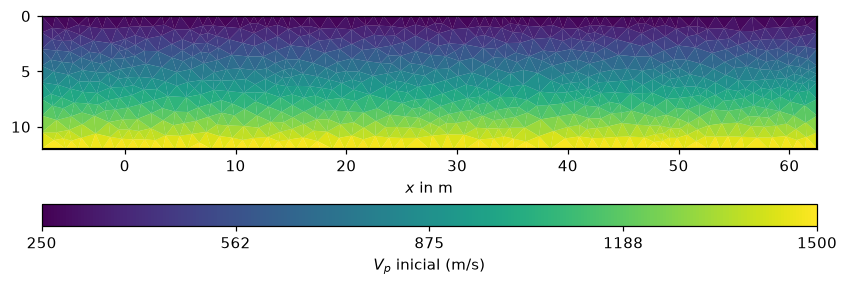

In [22]:
start_slowness = tt.createGradientModel2D(data_tt, mesh, V_TOP, V_BOTTOM)
v_start = 1 / np.array(start_slowness)
print(f"modelo inicial: {v_start.min():.0f} – {v_start.max():.0f} m/s")
ax, cb = pg.show(mesh, v_start, cMap="viridis", cMin=250, cMax=1500, label="$V_p$ inicial (m/s)")
ax.figure.set_size_inches(8, 3.2); plt.show()

### 5.5 Inversión de control de calidad (QC) y rechazo de picks atípicos

Se invierte una primera vez con **todos** los picks. Cada pick tiene un **residuo** $r_i=d_i-f_i(\hat{\mathbf m})$. Un pick erróneo (salto de ciclo, onda equivocada, fuente mal ubicada) no puede ser explicado por un modelo suave y regularizado, y deja un residuo grande. Se descartan los picks con $|r_i|>$ `MAX_RESIDUAL` (10 ms, ≈ 3σ), y se re-invierte.

23/10/26 - 10:00:17 - Core - ERROR - no cWeights defined. You should create constraints matrix first.


Inversion finished: chi2 = 1.82, Vp = 369-1518 m/s (mean 1211 m/s)
historial de χ² por iteración (la entrada 0 es el modelo inicial): [23.1   2.2   1.84  1.82]


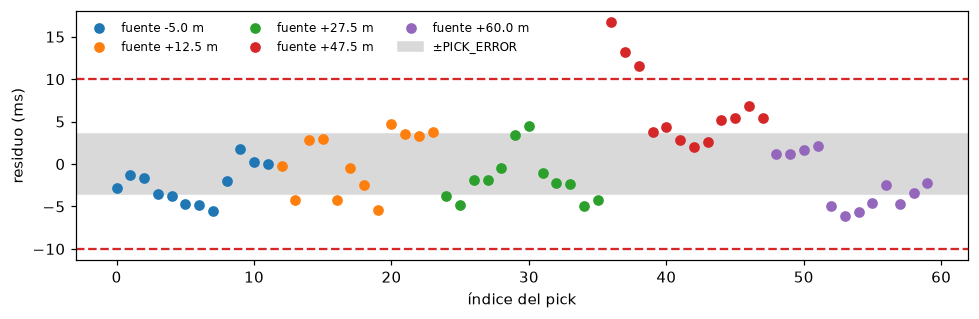

RMS del residuo = 4.73 ms


In [23]:
manager_qc = refraction.invert_tomography(
    data_tt, mesh=mesh, lam=LAM, z_weight=Z_WEIGHT, v_top=V_TOP, v_bottom=V_BOTTOM,
    correlation_lengths=CORR_LENGTHS,
)
print("historial de χ² por iteración (la entrada 0 es el modelo inicial):",
      np.round(manager_qc.inv.chi2History, 2))

res_qc = np.array(data_tt["t"]) - np.array(manager_qc.inv.response)
src_x = sensors_x[np.array(data_tt["s"], dtype=int)]
fig, ax = plt.subplots(figsize=(9, 3))
for k, sx in enumerate(np.unique(src_x)):
    m = src_x == sx
    ax.plot(np.where(m)[0], res_qc[m] * 1e3, "o", label=f"fuente {sx:+.1f} m", color=f"C{k}")
ax.axhspan(-PICK_ERROR * 1e3, PICK_ERROR * 1e3, color="0.85", label="±PICK_ERROR")
for sgn in (1, -1):
    ax.axhline(sgn * MAX_RESIDUAL * 1e3, color="C3", ls="--")
ax.set_xlabel("índice del pick"); ax.set_ylabel("residuo (ms)"); ax.legend(frameon=False, fontsize=8, ncol=3)
plt.tight_layout(); plt.show()
print(f"RMS del residuo = {np.sqrt(np.mean(res_qc**2))*1e3:.2f} ms")

In [24]:
picks_clean = refraction.drop_outlier_picks(gathers, picks, manager_qc, data_tt, max_residual=MAX_RESIDUAL)

Dropped pick: shot +47.5 m, receiver 0.0 m (residual +16.7 ms)
Dropped pick: shot +47.5 m, receiver 5.0 m (residual +13.2 ms)
Dropped pick: shot +47.5 m, receiver 10.0 m (residual +11.6 ms)


**Lectura.** Los tres picks descartados pertenecen todos al disparo de 47.5 m (los receptores más lejanos, 0–10 m, con residuos de +12 a +17 ms: llegadas *más tardías* de lo que predice el modelo). Posibles causas: ruido en trazas débiles de offset largo, un pick tardío (segundo lóbulo), o **posición de la fuente errónea**. Esta última merece una prueba: invertimos con la fuente colocada en 42.5, 45, 47.5 y 50 m.

In [25]:
import contextlib, io
rows = []
for sx in [42.5, 45.0, 47.5, 50.0]:
    with contextlib.redirect_stdout(io.StringIO()):           # silencia los mensajes de lectura/inversión
        g_alt = seg2_io.read_line(DATA_FOLDER, source_x_overrides={"2026-10-08_RF_47.5m.dat": sx})
    p_alt = refraction.pick_line(g_alt, v_min=PICK_V_MIN, v_max=PICK_V_MAX,
                                 noise_window=PICK_NOISE_WINDOW, threshold=PICK_THRESHOLD)
    with contextlib.redirect_stdout(io.StringIO()):
        d_alt = refraction.build_traveltime_data(g_alt, p_alt, pick_error=PICK_ERROR)
        m_alt = refraction.invert_tomography(d_alt, para_dx=PARA_DX, para_depth=PARA_DEPTH, quality=MESH_QUALITY,
                                             max_cell_size=MAX_CELL_SIZE, para_boundary=PARA_BOUNDARY, lam=LAM,
                                             z_weight=Z_WEIGHT, v_top=V_TOP, v_bottom=V_BOTTOM,
                                             correlation_lengths=CORR_LENGTHS)
    r = np.array(d_alt["t"]) - np.array(m_alt.inv.response)
    rows.append({"x fuente (m)": sx, "χ²": m_alt.inv.chi2(), "RMS residuo (ms)": np.sqrt(np.mean(r**2)) * 1e3,
                 "picks con |r| > MAX_RESIDUAL": int((np.abs(r) > MAX_RESIDUAL).sum())})
pd.DataFrame(rows).round(2)

23/10/26 - 10:00:21 - Core - ERROR - no cWeights defined. You should create constraints matrix first.


23/10/26 - 10:00:26 - Core - ERROR - no cWeights defined. You should create constraints matrix first.


23/10/26 - 10:00:31 - Core - ERROR - no cWeights defined. You should create constraints matrix first.


23/10/26 - 10:00:36 - Core - ERROR - no cWeights defined. You should create constraints matrix first.


,x fuente (m),χ²,RMS residuo (ms),picks con |r| > MAX_RESIDUAL
0,42.5,2.06,5.02,3
1,45.0,1.72,4.59,3
2,47.5,1.82,4.73,3
3,50.0,1.35,4.07,2


**El χ² no discrimina la posición de la fuente** (las diferencias son pequeñas y no son monótonas: el mejor χ² no cae en 47.5 m). Con tan pocos datos y una regularización fuerte, el modelo se adapta a casi cualquier ubicación razonable. La posición de la fuente se debe fijar con **evidencia independiente** (cinta, fotos, el registro de amplitudes de la sección 2), no con la inversión. Aquí se mantiene 47.5 m, apoyado en esa evidencia de amplitudes.

### 5.6 Inversión final

Se vuelve a construir el contenedor con los picks limpios (57) y se invierte de nuevo con los mismos parámetros.

In [26]:
data_clean = refraction.build_traveltime_data(gathers, picks_clean, pick_error=PICK_ERROR)
manager = refraction.invert_tomography(
    data_clean, para_dx=PARA_DX, para_depth=PARA_DEPTH,
    quality=MESH_QUALITY, max_cell_size=MAX_CELL_SIZE, para_boundary=PARA_BOUNDARY,
    lam=LAM, z_weight=Z_WEIGHT, v_top=V_TOP, v_bottom=V_BOTTOM,
    correlation_lengths=CORR_LENGTHS,
)
print("historial de χ²:", np.round(manager.inv.chi2History, 2))

Traveltime data: 17 sensors, 57 picks
Mesh: 1510 cells, 826 nodes (paraDX=0.33, depth=12.0 m, quality=33.5)


23/10/26 - 10:00:41 - Core - ERROR - no cWeights defined. You should create constraints matrix first.




Inversion finished: chi2 = 1.00, Vp = 373-1492 m/s (mean 1266 m/s)
historial de χ²: [24.23  1.55  1.2   1.12  1.03  1.  ]


#### El tomograma

`v_exag=0.1` comprime la escala horizontal respecto a la vertical (10×): sin esa exageración vertical, 12 m de profundidad serían diminutos junto a 65 m de ancho. **Atención:** los colores muestran toda la malla, incluyendo zonas sin rayos, donde el valor **no es una medición** (extrapolación de la regularización). Lo muestra el mapa de cobertura que sigue.

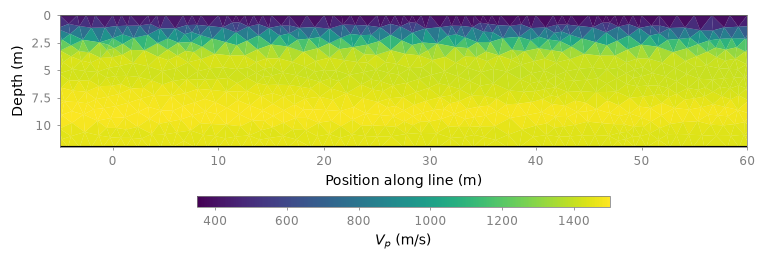

In [27]:
plotting.plot_tomogram(
    manager, width=7.0, height=2.2, fontsize=8, label_size=9, tick_size=8,
    cmap="viridis", v_min=None, v_max=None, show_mesh=None, v_exag=0.1,
    cbar_label="$V_{p}$ (m/s)", cbar_thickness=0.1,
    mesh_color="k", mesh_alpha=0.3, mesh_width=0.2,
    rays=None, ray_color="w", ray_alpha=0.5, ray_width=0.5,
    axis_color="#7f7f7f", label_color="k",
    xlim=(-5, 60), title=None,
)
plt.show()

#### Cobertura de rayos: ¿dónde confiar en el modelo?

La **cobertura** de una celda es la suma de longitudes de rayo que la atraviesan, $\sum_i L_{ij}$ (columna $j$ de la jacobiana). Si es 0, la celda no tiene ningún dato y su valor viene solo del modelo inicial y la regularización. Mostramos la cobertura en escala logarítmica y las velocidades solo donde hay rayos.

celdas con rayos: 581 de 1510


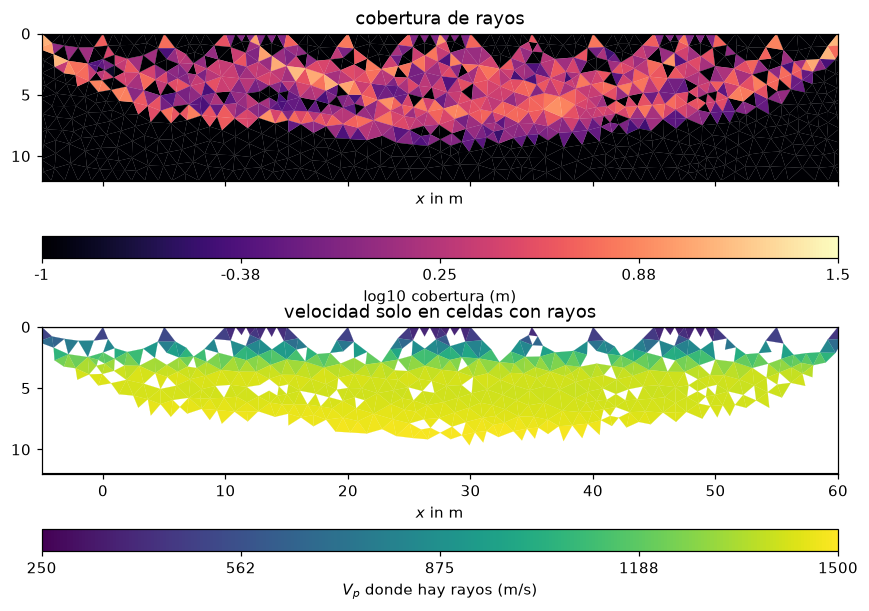

In [28]:
cov_cells = np.array(manager.rayCoverage())
vel_cells = np.array(manager.velocity)
print(f"celdas con rayos: {(cov_cells > 0).sum()} de {len(cov_cells)}")

fig, axes = plt.subplots(2, 1, figsize=(8, 5.5), sharex=True)
pg.show(manager.paraDomain, np.log10(cov_cells + 1e-3), ax=axes[0], cMap="magma", cMin=-1, cMax=1.5,
        label="log10 cobertura (m)", logScale=False)
masked = np.where(cov_cells > 0, vel_cells, np.nan)
pg.show(manager.paraDomain, masked, ax=axes[1], cMap="viridis", cMin=250, cMax=1500, label="$V_p$ donde hay rayos (m/s)")
axes[0].set_title("cobertura de rayos"); axes[1].set_title("velocidad solo en celdas con rayos")
for a in axes:
    a.set_xlim(-5, 60); a.set_ylim(-12, 0)
plt.tight_layout(); plt.show()

**Regla práctica:** las velocidades en celdas sin cobertura (o con cobertura baja) **no son una medición**. En este tendido los rayos llegan a ≈ 8–9 m de profundidad bajo el centro y solo a ≈ 3–5 m hacia los extremos; por debajo, el color del tomograma (≈ 1450–1500 m/s) es extrapolación de la regularización, no un resultado de los datos. Por eso conviene limitar la interpretación a profundidades con cobertura (la sección 6 lo comprueba en el perfil $V_p(z)$ central).

#### Comprobaciones finales

**(1) Observado vs predicho.** Si el modelo es adecuado los puntos caen sobre la recta 1:1 con dispersión ≈ `PICK_ERROR`.

**(2) La jacobiana reproduce los tiempos.** Verifiquemos $\mathbf t=\mathbf J\,\mathbf s$ con la matriz de longitudes que pyGIMLi guarda tras la última iteración.

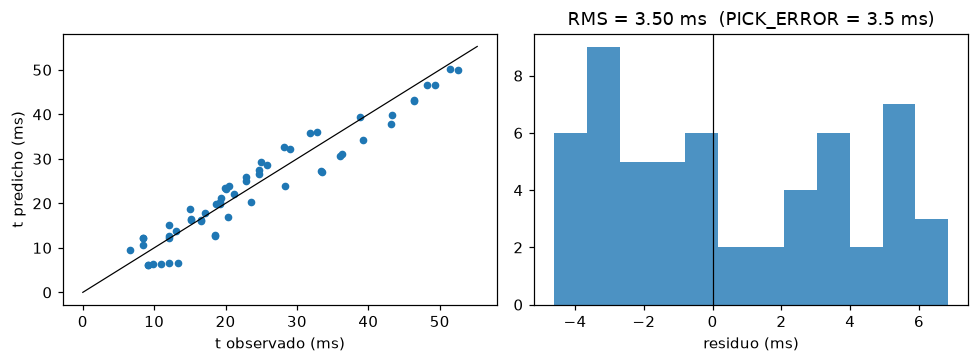

J tiene forma (57, 1510);  máx |J·s − respuesta| = 0.58 ms (1.1 % del tiempo máximo)
longitud total del primer rayo (suma de la fila 0) = 5.93 m; su offset es 5 m (el camino numérico es algo más largo que la recta por la discretización de la malla)


In [29]:
t_obs = np.array(data_clean["t"]); t_pred = np.array(manager.inv.response)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
axes[0].plot(t_obs * 1e3, t_pred * 1e3, "o", ms=4)
lim = [0, t_obs.max() * 1e3 * 1.05]; axes[0].plot(lim, lim, "k-", lw=0.8)
axes[0].set_xlabel("t observado (ms)"); axes[0].set_ylabel("t predicho (ms)")
r = (t_obs - t_pred) * 1e3
axes[1].hist(r, bins=12, color="C0", alpha=0.8); axes[1].axvline(0, color="k", lw=0.8)
axes[1].set_xlabel("residuo (ms)"); axes[1].set_title(f"RMS = {np.sqrt(np.mean(r**2)):.2f} ms  (PICK_ERROR = {PICK_ERROR*1e3:.1f} ms)")
plt.tight_layout(); plt.show()

J = pg.utils.sparseMatrix2coo(manager.fop.jacobian())          # N × M (m): longitudes del rayo en cada celda
s_model = 1 / np.array(manager.velocity)
t_J = J @ s_model
print(f"J tiene forma {J.shape};  máx |J·s − respuesta| = {np.abs(t_J - t_pred).max()*1e3:.2f} ms "
      f"({np.abs(t_J - t_pred).max() / t_pred.max() * 100:.1f} % del tiempo máximo)")
print(f"longitud total del primer rayo (suma de la fila 0) = {np.asarray(J.sum(axis=1)).ravel()[0]:.2f} m; su offset es 5 m "
      f"(el camino numérico es algo más largo que la recta por la discretización de la malla)")

**Cómo leer los residuos.** Lo deseable es un residuo aleatorio de ≈ `PICK_ERROR`. Si tiene estructura (por ejemplo, signo constante por disparo), el modelo **no puede explicar algo sistemático**: una posición de fuente errada, una variación lateral que la regularización aplanó, o un sesgo de picado.

En este caso el RMS (≈ 3.5 ms) coincide con `PICK_ERROR` **casi por construcción** (ese valor se tomó del piso de residuos y la inversión se detiene en $\chi^2\le1$), y el gráfico de residuos de la sección 5.5 muestra **estructura por disparo**: los disparos de −5 y 60 m quedan mayormente con residuo negativo (el modelo predice tiempos algo mayores que los observados) y el de 47.5 m con residuo positivo. Es una señal de que un modelo casi lateralmente uniforme (`CORR_LENGTHS=[80, 1]`) no explica por completo las diferencias entre disparos. En la sección 7 se prueba si permitir más variación lateral lo corrige.

> Nota sobre el mensaje rojo `no cWeights defined`: es un aviso interno de pyGIMLi que aparece al iniciar la inversión con regularización geoestadística (la matriz de restricciones se crea justo después). Los resultados sí dependen de `CORR_LENGTHS` y de `LAM` (se demuestra en la sección 7), así que la regularización se está aplicando.

## 6. Interpretación conjunta: $V_p$ (refracción) + $V_s$ (MASW)

La refracción da $V_p$; el análisis MASW (ondas superficiales, hecho aparte) da $V_s$. Juntas permiten estimar propiedades elásticas y distinguir *rigidez* (gobernada por $V_s$) de *saturación* (que afecta a $V_p$ pero casi no a $V_s$).

### 6.1 Perfil 1D de $V_p(z)$ bajo el centro del tendido

`vp_profile_from_tomogram` interpola el tomograma 2D a lo largo de una **línea vertical** en `X_CENTER` (27.5 m), entre `Z_MIN_INTERP` y `Z_MAX_INTERP`, en 40 profundidades equiespaciadas. Se empieza a 0.5 m porque las celdas más someras están mal resueltas por el picado a 2.5 m de offset, y se termina a 10 m. Junto al perfil mostramos si cada punto está **cubierto por rayos**, para saber hasta dónde es una medición:

paso en profundidad = 0.244 m;  última profundidad con rayos bajo x = 27.5 m: 7.3 m


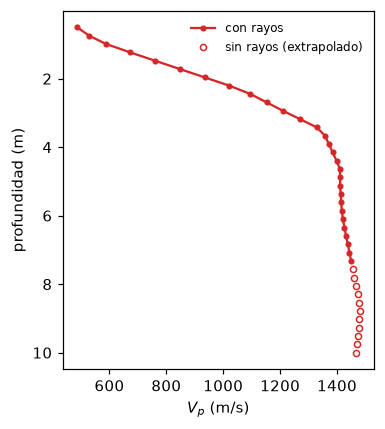

In [30]:
vp_profile = interpretation.vp_profile_from_tomogram(manager, x_center=X_CENTER, z_min=Z_MIN_INTERP, z_max=Z_MAX_INTERP)

cov_cells = np.array(manager.rayCoverage())
def covered_at(z):
    cell = manager.paraDomain.findCell(pg.Pos(X_CENTER, -z))
    return bool(cell is not None and cov_cells[cell.id()] > 0)
vp_profile["con_rayos"] = [covered_at(z) for z in vp_profile["depth_m"]]

z_last = vp_profile.loc[vp_profile["con_rayos"], "depth_m"].max()
print(f"paso en profundidad = {vp_profile['depth_m'].diff().iloc[1]:.3f} m;  "
      f"última profundidad con rayos bajo x = {X_CENTER} m: {z_last:.1f} m")

fig, ax = plt.subplots(figsize=(3.6, 4))
c = vp_profile["con_rayos"].to_numpy()
ax.plot(vp_profile.vp_m_s[c], vp_profile.depth_m[c], "o-", color="C3", ms=3, label="con rayos")
ax.plot(vp_profile.vp_m_s[~c], vp_profile.depth_m[~c], "o", mfc="none", color="C3", ms=4, label="sin rayos (extrapolado)")
ax.invert_yaxis(); ax.set_xlabel("$V_p$ (m/s)"); ax.set_ylabel("profundidad (m)"); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

**Lectura.** Bajo el centro, $V_p$ sube rápido en los primeros metros (≈ 760 m/s a 1.5 m, ≈ 1100 m/s a 2.4 m, ≈ 1400 m/s hacia los 4.4 m) y luego casi se estabiliza en ≈ 1450–1480 m/s. Los rayos solo llegan hasta ≈ 7 m bajo el centro (ver la salida de arriba), así que **lo que hay debajo es extrapolación/regularización, no medición**. Esos ≈ 1400–1500 m/s están **cerca de la velocidad de la onda P en agua (~1480 m/s)**: en un suelo saturado, $V_p$ está dominada por el agua de los poros y *deja de ser sensible a la rigidez del esqueleto*. Es el hallazgo clave para interpretar la sección: $V_p$ ≈ 1450 m/s indica **nivel freático cercano**, no un material necesariamente duro. Los puntos sin rayos (círculos vacíos) no se deben interpretar; el perfil conjunto de abajo sí los usa hasta 10 m (`Z_MAX_INTERP`), por lo que **la parte más profunda de las propiedades elásticas depende de $V_p$ extrapolado**.

### 6.2 El perfil de $V_s$ (MASW)

`MASW_vs_profile.csv` contiene $V_s(z)$ de la inversión de la curva de dispersión. Solo es fiable hasta unos 14 m de profundidad: por debajo, el archivo trae **valores negativos o absurdos** (artefacto de la inversión), que aquí no se usan: `elastic_properties` solo conserva las profundidades presentes en *ambos* perfiles ($V_p$ cubre 0.5–10 m y $V_s$ arranca en 1.36 m), de modo que el resultado queda entre ≈ 1.4 y 10 m. $V_s$ se interpola linealmente sobre las profundidades de $V_p$.

Vs: 100 puntos, profundidad 1.36–15.00 m
puntos con Vs ≤ 0 (inservibles): 3, el primero a 14.7 m de profundidad


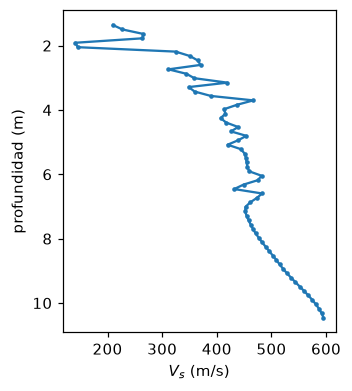

In [31]:
vs_profile = pd.read_csv(MASW_VS_CSV)
print(f"Vs: {len(vs_profile)} puntos, profundidad {vs_profile.depth_m.min():.2f}–{vs_profile.depth_m.max():.2f} m")
bad = vs_profile[vs_profile.vs_m_s <= 0]
print(f"puntos con Vs ≤ 0 (inservibles): {len(bad)}, el primero a {bad.depth_m.min():.1f} m de profundidad")
vs_profile[vs_profile.depth_m <= 10.5].plot(x="vs_m_s", y="depth_m", figsize=(3.2, 3.8), legend=False, marker="o", ms=2, color="C0")
plt.gca().invert_yaxis(); plt.xlabel("$V_s$ (m/s)"); plt.ylabel("profundidad (m)"); plt.show()

### 6.3 De $(V_p,V_s)$ a propiedades elásticas

Para un medio elástico isótropo con densidad $\rho$ y parámetros de Lamé $\lambda,\mu$:

$$V_p^2=\frac{\lambda+2\mu}{\rho},\qquad V_s^2=\frac{\mu}{\rho}\quad\Rightarrow\quad r^2\equiv\left(\frac{V_p}{V_s}\right)^2=\frac{\lambda}{\mu}+2.$$

**Módulo de corte:** $\;G=\mu=\rho\,V_s^2$.

**Razón de Poisson** $\nu=\dfrac{\lambda}{2(\lambda+\mu)}$. Con $\lambda/\mu=r^2-2$:

$$\nu=\frac{r^2-2}{2\,(r^2-1)}.$$

Límites: $r=\sqrt2\Rightarrow\nu=0$; $r\to\infty\Rightarrow\nu\to0.5$ (incompresible, típico de suelo saturado). Como $\nu\ge0$ para un sólido elástico, **$V_s\le V_p/\sqrt2$**; `elastic_properties` recorta $V_s$ a ese límite.

**Módulo de Young:** $E=2G\,(1+\nu)$.

Las unidades: $\rho$ en kg/m³ y $V$ en m/s dan Pa; el código divide entre $10^6$ para obtener **MPa**.

**Avisos de interpretación:**

* Son módulos **dinámicos** (deformaciones ~$10^{-6}$): típicamente 2–10× mayores que los módulos estáticos de ingeniería.
* $\rho=1800$ kg/m³ es un **supuesto**. $G$ y $E$ son proporcionales a $\rho$: si cambias `RHO` un 10 %, cambian un 10 %. $\nu$ no depende de $\rho$.
* Como $d\nu/dr = r/(r^2-1)^2$, para $r\approx3.2$ un error de 10 % en $r$ (≈ 0.3) solo mueve $\nu$ ≈ 0.01. Es decir, $\nu$ **se satura** cerca de 0.44–0.46 y casi no discrimina entre materiales una vez que $V_p$ está dominada por el agua; úsalo solo como indicador cualitativo de saturación. En cambio $G$ (y $E$) dependen del *cuadrado* de $V_s$: un error de 10 % en $V_s$ es ≈ 20 % en $G$.

In [32]:
properties = interpretation.elastic_properties(vp_profile, vs_profile, rho=RHO)

# Comprobación manual en una profundidad (la más cercana a 5 m)
row = properties.iloc[(properties.depth_m - 5.0).abs().argmin()]
vp_, vs_ = row.vp_m_s, row.vs_m_s
r_ = vp_ / vs_
nu_ = (r_**2 - 2) / (2 * (r_**2 - 1))
G_ = RHO * vs_**2 / 1e6
E_ = 2 * G_ * (1 + nu_)
print(f"z = {row.depth_m:.2f} m:  Vp = {vp_:.0f} m/s, Vs = {vs_:.0f} m/s")
print(f"  Vp/Vs = {r_:.2f}   ν = {nu_:.3f}   G = {G_:.0f} MPa   E = {E_:.0f} MPa")
assert np.allclose([r_, nu_, G_, E_], [row.vp_vs_ratio, row.poisson_ratio, row.shear_modulus_MPa, row.youngs_modulus_MPa])
print("OK: coincide con elastic_properties\n")
properties.round(3).iloc[::4]

z = 4.88 m:  Vp = 1410 m/s, Vs = 445 m/s
  Vp/Vs = 3.17   ν = 0.445   G = 357 MPa   E = 1031 MPa
OK: coincide con elastic_properties



,depth_m,vp_m_s,vs_m_s,vp_vs_ratio,poisson_ratio,shear_modulus_MPa,youngs_modulus_MPa
0,1.474,759.513,224.356,3.385,0.452,90.604,263.151
4,2.449,1095.604,363.783,3.012,0.438,238.208,685.108
8,3.423,1328.948,358.924,3.703,0.461,231.888,677.417
12,4.397,1398.206,418.114,3.344,0.451,314.674,913.120
16,5.372,1412.615,451.212,3.131,0.443,366.466,1057.761
20,6.346,1425.867,445.658,3.199,0.446,357.500,1033.796
24,7.321,1449.362,455.338,3.183,0.445,373.198,1078.727
28,8.295,1472.790,491.493,2.997,0.437,434.818,1249.960
32,9.269,1476.516,539.173,2.738,0.423,523.273,1489.307


### 6.4 Clasificación de materiales

`classify_materials` asigna a cada profundidad una clase **solo por $V_s$** (rigidez), siguiendo rangos de práctica geotécnica (tipo NEHRP), y añade una etiqueta de **posible saturación** si $\nu>0.45$:

| $V_s$ (m/s) | clase |
|---|---|
| < 180 | suelo blando: césped, capa vegetal suelta |
| 180–360 | suelo firme: relleno arenoso/arcilloso compactado |
| 360–760 | suelo muy denso / subbase gravosa |
| 760–1500 | roca meteorizada / blanda |

Como $V_s$ es ruidosa (viene de un picado de curva de dispersión), antes de clasificar se aplica:

1. **Filtro de mediana** de 5 puntos sobre $V_s$ y $\nu$ (elimina picos aislados sin desplazar los bordes, a diferencia de una media móvil).
2. **Fusión de capas delgadas:** cualquier tramo de menos de `min_thickness` = 1 m (en número de muestras, con el paso de ≈ 0.24 m) se absorbe en la capa de arriba (el tramo superior se funde con el de abajo).

**Detalle a conocer:** `scipy.signal.medfilt` rellena los bordes con ceros, por lo que las primeras y últimas 2 muestras suavizadas salen **sesgadas hacia abajo** (verás abajo $V_s$ suavizada = 143 m/s en la primera muestra frente a 224 m/s cruda). Aquí el efecto lo absorbe la fusión de capas delgadas, pero es un artefacto, no un dato.

Veamos el efecto de cada paso: clasificación *sin* suavizado frente a la final.

In [33]:
from scipy.signal import medfilt

raw = interpretation.classify_materials(properties, smooth_points=1, min_thickness=0.0)   # sin suavizado ni fusión
layers = interpretation.classify_materials(properties)                                      # parámetros por defecto
print(f"sin suavizado ni fusión: {len(raw)} capas   |   con filtro de mediana (5) y fusión (1 m): {len(layers)} capas\n")

vs_smooth = medfilt(properties.vs_m_s.to_numpy(), 5)
print("Vs cruda vs. suavizada (primeras 12 profundidades):")
print(pd.DataFrame({"z (m)": properties.depth_m, "Vs cruda": properties.vs_m_s, "Vs mediana": vs_smooth}).head(12).round(2).to_string(index=False))
print("\nCapas finales:")
layers.drop(columns="color")

sin suavizado ni fusión: 11 capas   |   con filtro de mediana (5) y fusión (1 m): 2 capas

Vs cruda vs. suavizada (primeras 12 profundidades):
 z (m)  Vs cruda  Vs mediana
  1.47    224.36      142.85
  1.72    264.39      224.36
  1.96    142.85      264.39
  2.21    328.21      328.21
  2.45    363.78      330.87
  2.69    330.87      350.76
  2.94    350.76      358.92
  3.18    404.90      358.92
  3.42    358.92      404.90
  3.67    446.74      413.36
  3.91    424.71      418.11
  4.15    413.36      424.71

Capas finales:


,top_m,bottom_m,vp_mean_m_s,vs_mean_m_s,poisson_mean,material
0,1.47,4.03,1122.0,331.0,0.45,Stiff soil: compacted sandy/clayey fill
1,4.03,10.00,1442.0,478.0,0.44,Very dense soil / gravelly subbase


**Lectura de la tabla de capas.** Con los parámetros por defecto quedan 2 capas (frente a 11 sin suavizado): relleno firme (≈ 1.5–4 m) sobre suelo muy denso (≈ 4–10 m). En ninguna el $\nu$ suavizado supera 0.45, así que no aparece la etiqueta de saturación, aunque $\nu$ es ≈ 0.44–0.46 y está justo en el umbral. Las capas resultantes son el producto combinado de *dos mediciones* y de reglas de suavizado. Cada etiqueta depende de los umbrales de `VS_CLASSES`: si $V_s$ cae cerca de un umbral (p.ej. 360 m/s) pequeños cambios de $V_s$ pueden mover una frontera de capa por metros. Lo que se interpreta con confianza es la **tendencia general**: material blando superficial y rigidez creciente con la profundidad; los **límites exactos de capa son aproximados**.

Para **manipular la clasificación** puedes: cambiar `VS_CLASSES` en `utils/interpretation.py` (rangos o nombres), `smooth_points`, `min_thickness` y `poisson_saturated` (umbral de saturación).

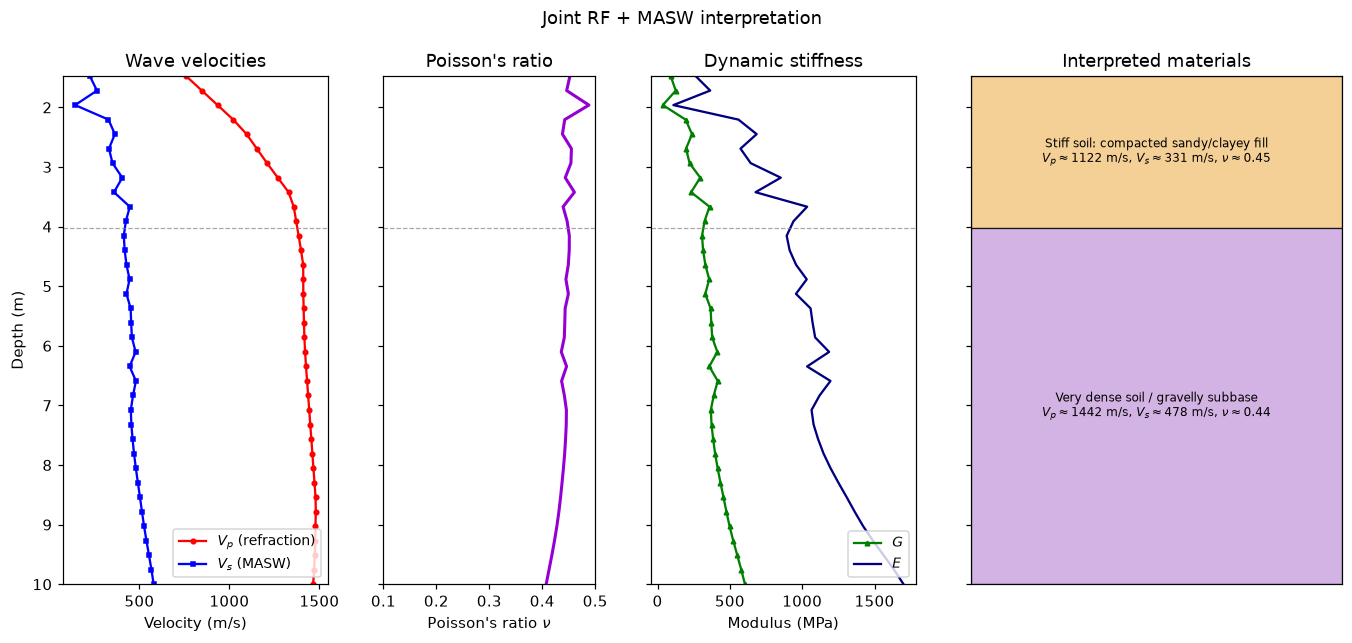

In [34]:
fig = interpretation.plot_interpretation(properties, layers)
plt.show()

## 7. Cómo manipular el procesamiento

### 7.1 Mapa de parámetros

Todos los parámetros están en la celda 0 (arriba del notebook). Qué hace cada uno y qué esperar al moverlo:

| Parámetro | Etapa | Qué controla | Si lo **subes** | Si lo **bajas** |
|---|---|---|---|---|
| `PICK_V_MIN`, `PICK_V_MAX` | picado | Ventana de búsqueda $[t_{prev}+\Delta x/v_{max},\;t_{prev}+\Delta x/v_{min}]$ | Ventana más ancha (`V_MIN` baja) admite picks tardíos; `V_MAX` alto admite picos tempranos (ruido) | Ventana estrecha: el picado queda "forzado" a una pendiente |
| `PICK_NOISE_WINDOW` | picado | Muestras iniciales usadas para estimar $\sigma$ del ruido | Mejor estadística, pero puede incluir señal temprana (disparos cercanos) | Más ruidoso; mínimo 8 muestras |
| `PICK_THRESHOLD` | picado | Disparo = umbral × $\sigma$ | Menos falsos picos, pero picks más **tardíos** | Picks más tempranos y más ruidosos |
| `PICK_OVERRIDES` | picado | Corrección manual de un pick | — | — |
| `PICK_ERROR` | datos | Incertidumbre $\varepsilon$ de cada tiempo; **también** pondera $\chi^2$ y el criterio de parada | Se detiene antes (modelo más suave, $\chi^2$ menor) | Fuerza ajustar más: $\chi^2$ sube, puede sobreajustar ruido |
| `PARA_DX`, `MESH_QUALITY`, `MAX_CELL_SIZE`, `PARA_DEPTH`, `PARA_BOUNDARY` | malla | Resolución y extensión del modelo | Celdas más finas: más parámetros, más lento, igual información | Celdas gruesas: no resuelven estructura somera |
| `LAM` | inversión | Peso de la regularización $\lambda$ | Modelo más suave/cercano al de referencia, peor ajuste | Mejor ajuste, modelo más rugoso, extremos irreales |
| `CORR_LENGTHS` $[I_x,I_z]$ | inversión | Escala de correlación del modelo | $I_x\gg I_z$ ⇒ capas horizontales | Valores iguales ⇒ estructura isotrópica |
| `Z_WEIGHT` | inversión | Penaliza gradientes verticales vs. horizontales (solo si `CORR_LENGTHS=None`) | $<1$ favorece capas horizontales | — |
| `V_TOP`, `V_BOTTOM` | inversión | Modelo inicial en gradiente y límites razonables | Fija el valor al que **tiende el modelo donde no hay rayos** | — |
| `MAX_RESIDUAL` | QC | Umbral para descartar picks tras la inversión | Descarta menos | Descarta más |
| `RHO` | interpretación | Densidad supuesta | $G,E$ proporcionales | — |
| `X_CENTER`, `Z_MIN_INTERP`, `Z_MAX_INTERP` | interpretación | Dónde se toma el perfil 1D | — | — |

**Regla práctica de orden de trabajo:** (1) arregla picks mirando los sismogramas; (2) fija `PICK_ERROR` a un valor físicamente razonable (1–4 ms aquí); (3) ajusta `LAM` y `CORR_LENGTHS` observando el modelo, el $\chi^2$ y la cobertura; (4) solo entonces interpreta.

### 7.2 Experimentos controlados

A continuación definimos `run_inversion(**cambios)`, que repite toda la inversión con los picks limpios cambiando *un* parámetro a la vez y devuelve las métricas que nos importan. Así separas el efecto de cada decisión.

Métricas:

* $\chi^2$ y RMS del residuo (ms): bondad de ajuste.
* **Sesgo por disparo** (ms): residuo medio $d_{obs}-d_{pred}$ de cada disparo. Un modelo con fuentes bien ubicadas debería dejarlos cerca de 0.
* $V_p$ a 2, 5 y 8 m bajo el centro: cuánto cambia lo que luego interpretas.
* Profundidad máxima con rayos bajo el centro.

In [35]:
def run_inversion(pick_error=PICK_ERROR, picks_in=None, **overrides):
    params = dict(para_dx=PARA_DX, para_depth=PARA_DEPTH, quality=MESH_QUALITY, max_cell_size=MAX_CELL_SIZE,
                  para_boundary=PARA_BOUNDARY, lam=LAM, z_weight=Z_WEIGHT, v_top=V_TOP, v_bottom=V_BOTTOM,
                  correlation_lengths=CORR_LENGTHS)
    params.update(overrides)
    pk = picks_clean if picks_in is None else picks_in
    with contextlib.redirect_stdout(io.StringIO()):
        d = refraction.build_traveltime_data(gathers, pk, pick_error=pick_error)
        m = refraction.invert_tomography(d, **params)
    res = np.array(d["t"]) - np.array(m.inv.response)
    src = np.array([d.sensorPosition(int(i))[0] for i in d["s"]])
    bias = {sx: 1e3 * res[src == sx].mean() for sx in np.unique(src)}
    vp = interpretation.vp_profile_from_tomogram(m, X_CENTER, Z_MIN_INTERP, Z_MAX_INTERP)
    cov = np.array(m.rayCoverage())
    zc = np.linspace(Z_MIN_INTERP, Z_MAX_INTERP, 60)
    cov_col = np.array([(m.paraDomain.findCell(pg.Pos(X_CENTER, -z)) is not None) and
                        cov[m.paraDomain.findCell(pg.Pos(X_CENTER, -z)).id()] > 0 for z in zc])
    z_cov = zc[cov_col].max() if cov_col.any() else np.nan
    info = dict(chi2=m.inv.chi2(), rms_ms=1e3 * np.sqrt(np.mean(res**2)), iters=len(m.inv.chi2History) - 1,
                Vp2=np.interp(2, vp.depth_m, vp.vp_m_s), Vp5=np.interp(5, vp.depth_m, vp.vp_m_s),
                Vp8=np.interp(8, vp.depth_m, vp.vp_m_s), z_cov=z_cov)
    return m, info, bias, vp

experimentos = {
    "base (LAM=100, [80,1])": {},
    "LAM = 10": dict(lam=10),
    "LAM = 1000": dict(lam=1000),
    "LAM = 10000": dict(lam=1e4),
    "CORR [20, 2]": dict(correlation_lengths=[20, 2]),
    "CORR [10, 10] (isótropo)": dict(correlation_lengths=[10, 10]),
    "V_BOTTOM = 3000": dict(v_bottom=3000.0),
    "CORR=None, Z_WEIGHT=0.3": dict(correlation_lengths=None, z_weight=0.3),
    "CORR=None, Z_WEIGHT=1, LAM=30": dict(correlation_lengths=None, z_weight=1.0, lam=30),
}
resultados = {name: run_inversion(**kw) for name, kw in experimentos.items()}
for name, pe in [("PICK_ERROR = 2 ms", 0.002), ("PICK_ERROR = 5 ms", 0.005), ("PICK_ERROR = 10 ms", 0.010)]:
    resultados[name] = run_inversion(pick_error=pe)

tabla = pd.DataFrame({name: {**info, **{f"sesgo {sx:g} m": b for sx, b in bias.items()}}
                      for name, (m, info, bias, vp) in resultados.items()}).T
tabla.round(2)

23/10/26 - 10:00:47 - Core - ERROR - no cWeights defined. You should create constraints matrix first.


23/10/26 - 10:00:53 - Core - ERROR - no cWeights defined. You should create constraints matrix first.


23/10/26 - 10:00:58 - Core - ERROR - no cWeights defined. You should create constraints matrix first.


23/10/26 - 10:01:05 - Core - ERROR - no cWeights defined. You should create constraints matrix first.


23/10/26 - 10:01:19 - Core - ERROR - no cWeights defined. You should create constraints matrix first.


...

23/10/26 - 10:01:29 - Core - ERROR - no cWeights defined. You should create constraints matrix first.


23/10/26 - 10:01:38 - Core - ERROR - no cWeights defined. You should create constraints matrix first.


23/10/26 - 10:01:48 - Core - ERROR - no cWeights defined. You should create constraints matrix first.


23/10/26 - 10:01:49 - Core - ERROR - no cWeights defined. You should create constraints matrix first.


,chi2,rms_ms,iters,Vp2,Vp5,Vp8,z_cov,sesgo -5 m,sesgo 12.5 m,sesgo 27.5 m,sesgo 47.5 m,sesgo 60 m
"base (LAM=100, [80,1])",1.00,3.50,5.0,947.91,1410.60,1465.78,7.42,-1.02,1.38,-0.64,5.19,-1.10
LAM = 10,1.06,3.60,5.0,914.67,1545.37,1616.24,7.10,-0.27,0.43,-2.03,3.11,-0.43
LAM = 1000,1.26,3.93,8.0,890.89,1333.08,1402.18,10.00,-1.57,1.70,-0.14,6.18,-1.09
LAM = 10000,1.67,4.52,16.0,843.67,1141.51,1514.82,10.00,-1.58,1.33,-0.82,5.80,-0.97
"CORR [20, 2]",1.04,3.57,5.0,875.23,1280.26,1363.30,7.42,-0.31,1.59,-0.40,4.82,-1.30
"CORR [10, 10] (isótropo)",1.60,4.43,4.0,1007.33,1087.76,1165.31,9.52,-0.04,2.64,1.53,6.68,-0.68
V_BOTTOM = 3000,0.93,3.37,6.0,977.42,1363.11,1415.12,3.56,-1.36,1.12,-0.76,4.91,-1.57
"CORR=None, Z_WEIGHT=0.3",0.96,3.44,2.0,1116.39,1285.85,1223.17,9.68,-0.16,1.67,0.83,4.14,-0.67
"CORR=None, Z_WEIGHT=1, LAM=30",1.26,3.93,4.0,1083.96,1140.45,1187.71,9.52,-0.07,2.25,1.51,5.35,-0.67
PICK_ERROR = 2 ms,2.55,3.19,9.0,1056.61,1385.29,1454.07,9.52,-0.58,1.14,-0.94,4.34,-1.23


**Cómo leer la tabla** (cifras de esta ejecución; si cambias algo, relee la tabla, no estos números):

* **`LAM`**: al subir de 10 a 10 000 el ajuste empeora monótonamente ($\chi^2$ de 1.06 a 1.67; con $\lambda\ge10^3$ ya no se alcanza $\chi^2\le1$) y el algoritmo necesita más iteraciones (5 → 16) y no llega a converger, mientras el modelo se vuelve más suave. Con `LAM=10` el modelo se rugosifica y $V_p$ a 8 m llega a ≈ 1600 m/s, **por encima de la velocidad del agua** y de lo que los datos justifican. `LAM=100` está en el rango donde $\chi^2\approx1$ sin extremos irreales.
* **`CORR_LENGTHS`**: pasar a $[10,10]$ (isótropo) **empeora el ajuste** ($\chi^2\approx1.6$) y reduce mucho $V_p$ a 5 y 8 m (≈ 1090 y 1170 m/s frente a ≈ 1410 y 1470 m/s): el modelo base *necesita* la geometría de capas anchas ($I_x\gg I_z$) para explicar los tiempos. Es una **hipótesis a priori** (capas casi horizontales) que influye en el resultado, no un dato.
* **`V_BOTTOM`**: casi no cambia el ajuste ($\chi^2$ = 0.93), pero cambia el modelo donde los rayos no llegan, y también **cambia dónde llegan los rayos**: la profundidad con cobertura bajo el centro (`z_cov`) pasa de ≈ 7.4 m a ≈ 3.6 m, porque los rayos viajan por donde el modelo es rápido. Moraleja: la cobertura es una propiedad *del modelo*, no solo de la geometría de adquisición, y los ≈ 1450–1500 m/s profundos dependen del modelo inicial y de la regularización.
* **`Z_WEIGHT` sin correlación**: otra forma de imponer capas, pero produce un modelo con estructura lateral y un perfil casi plano (≈ 1100–1300 m/s entre 2 y 8 m) bastante distinto del base; la **forma de regularizar** es una decisión interpretativa.
* **`PICK_ERROR`**: con 2 ms el $\chi^2\approx2.5$ (ajusta peor de lo exigido y trabaja 9 iteraciones); con 5 ms o más la inversión **se detiene tras 1 iteración** porque $\chi^2\le1$ casi desde el principio, y el RMS del residuo sube a ≈ 5 ms. Lo importante: **`PICK_ERROR` no es solo un peso estadístico, también es un control de parada**, y con valores grandes el modelo queda poco evolucionado (Vp a 5 m ≈ 1030–1115 m/s frente a ≈ 1410 m/s). No lo uses para "mejorar el $\chi^2$".
* **Sesgo del disparo en 47.5 m**: es positivo en *todos* los experimentos (≈ +2.5 a +7 ms); en los que ajustan bien ($\chi^2\lesssim1.3$ y varias iteraciones) los demás disparos quedan en ±2 ms. Ninguno de los parámetros de regularización lo corrige; sugiere un error sistemático ligado a ese disparo (posición declarada, tiempo de disparo/trigger…), ver sección 8.

/home/orincon/miniconda3/envs/seismic-l1/lib/python3.12/site-packages/pygimli/viewer/mpl/utils.py:168: UserWarning: The figure layout has changed to tight
  ax.figure.tight_layout()


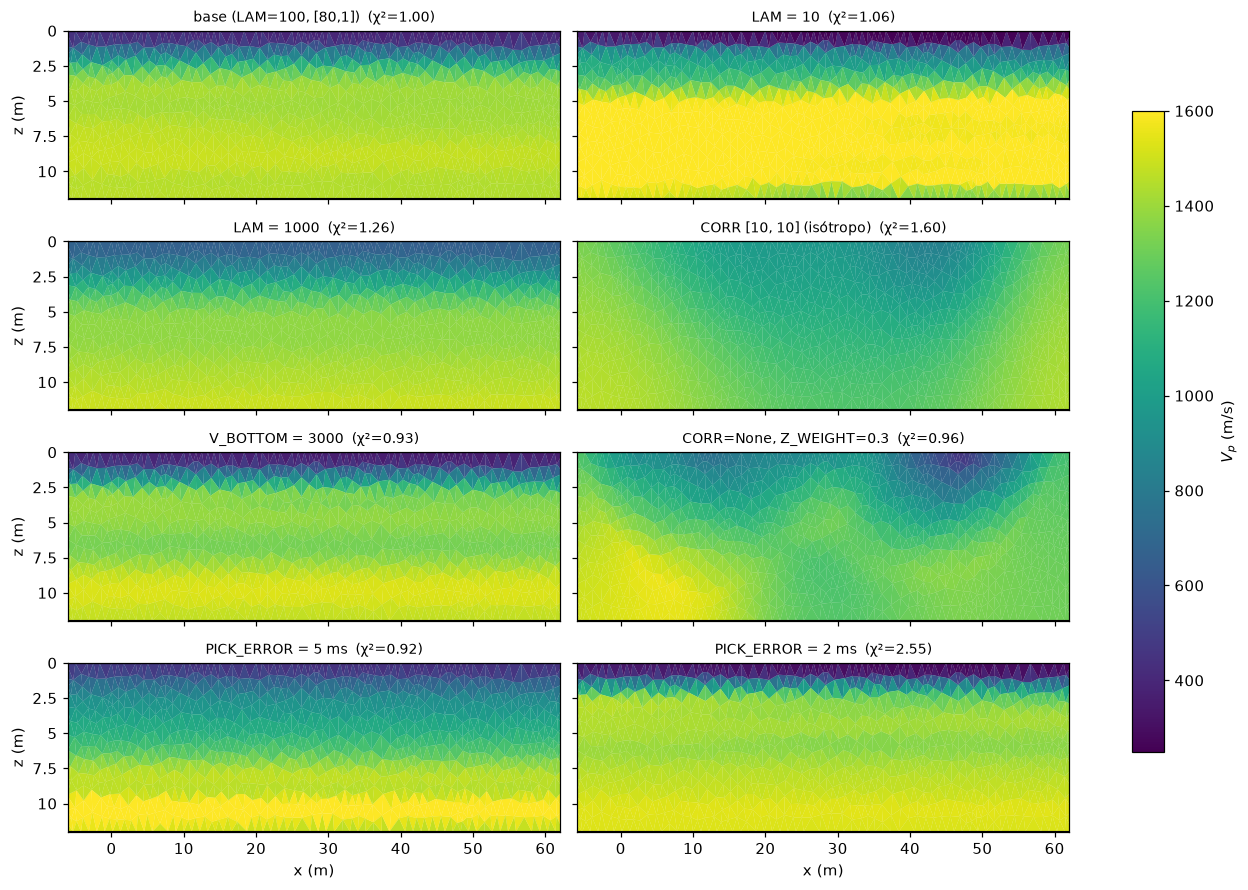

In [36]:
nombres = ["base (LAM=100, [80,1])", "LAM = 10", "LAM = 1000", "CORR [10, 10] (isótropo)",
           "V_BOTTOM = 3000", "CORR=None, Z_WEIGHT=0.3", "PICK_ERROR = 5 ms", "PICK_ERROR = 2 ms"]
fig, axes = plt.subplots(4, 2, figsize=(12, 8), sharex=True, sharey=True, constrained_layout=True)
for ax, name in zip(axes.ravel(), nombres):
    m = resultados[name][0]
    pg.show(m.paraDomain, np.array(m.velocity), ax=ax, cMin=250, cMax=1600, cMap="viridis",
            colorBar=False, logScale=False, coverage=None)
    ax.set_title(f"{name}  (χ²={resultados[name][1]['chi2']:.2f})", fontsize=9)
    ax.set_xlim(-6, 62); ax.set_ylim(-12, 0)
    ax.set_xlabel(""); ax.set_ylabel(""); ax.set_aspect("auto")
sm = plt.cm.ScalarMappable(cmap="viridis", norm=plt.Normalize(250, 1600))
fig.colorbar(sm, ax=axes, label="$V_p$ (m/s)", shrink=0.8)
for ax in axes[-1]: ax.set_xlabel("x (m)")
for ax in axes[:, 0]: ax.set_ylabel("z (m)")
plt.show()

**Qué mirar en la rejilla:** (1) los modelos con correlación anisotrópica ($I_x\gg I_z$: base, `LAM`, `V_BOTTOM`) son capas casi horizontales con el mismo patrón general: lento arriba y ≈ 1300–1600 m/s por debajo de ≈ 4 m; (2) `CORR [10,10]` y `Z_WEIGHT=0.3` generan **estructura lateral** (zonas lentas hacia x ≈ 30–50 m y más rápidas en los bordes) que los datos no distinguen del modelo en capas: con solo 5 disparos la 2D lateral no está bien determinada; (3) en la zona profunda el color cambia según `LAM`, `V_BOTTOM` y la correlación aunque los datos sean los mismos: eso es *información a priori*, no medición. (Nótese que la escala de color satura en 1600 m/s.)

Comparemos los perfiles $V_p(z)$ bajo el centro y la profundidad hasta la que hay rayos:

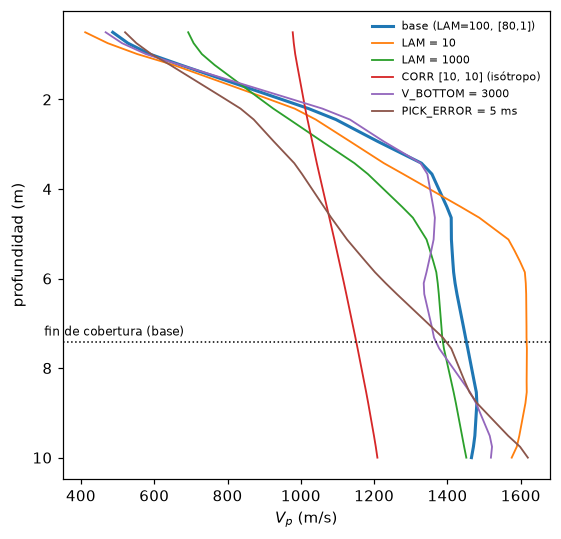

In [37]:
fig, ax = plt.subplots(figsize=(5.2, 5))
for name in ["base (LAM=100, [80,1])", "LAM = 10", "LAM = 1000", "CORR [10, 10] (isótropo)", "V_BOTTOM = 3000", "PICK_ERROR = 5 ms"]:
    vp = resultados[name][3]
    ax.plot(vp.vp_m_s, vp.depth_m, label=name, lw=2 if name.startswith("base") else 1.2)
ax.axhline(resultados["base (LAM=100, [80,1])"][1]["z_cov"], color="k", ls=":", lw=1)
ax.text(300, resultados["base (LAM=100, [80,1])"][1]["z_cov"] - 0.15, "fin de cobertura (base)", fontsize=8)
ax.invert_yaxis(); ax.set_xlabel("$V_p$ (m/s)"); ax.set_ylabel("profundidad (m)")
ax.legend(fontsize=7, frameon=False); plt.tight_layout(); plt.show()

**Moraleja.** Lo robusto es la forma general: $V_p$ baja en el primer metro y creciente con fuerza hasta ≈ 4 m. Lo **no robusto** es el valor entre 4 y 10 m: entre los experimentos que ajustan bien ($\chi^2\le1.3$) $V_p$ va de ≈ 1140 a ≈ 1545 m/s a 5 m y de ≈ 1190 a ≈ 1620 m/s a 8 m, y a 2 m de ≈ 875 a ≈ 1115 m/s. Por eso las propiedades elásticas profundas del §6 deben leerse con cautela.

### 7.3 Tabla de síntomas → causa probable → qué hacer

| Síntoma | Causa probable | Acción |
|---|---|---|
| Picks que saltan hacia atrás o están cerca de $t=0$ | `PICK_NOISE_WINDOW` contiene señal, o el *walk-back* baja del umbral | Revisa con el gráfico de trazas; acorta la ventana o usa `PICK_OVERRIDES` |
| Receptores equidistantes con tiempos casi idénticos | Ventana de búsqueda colapsada ($\Delta x/v$ igual) | Amplía `PICK_V_MIN`–`PICK_V_MAX` o corrige a mano |
| $\chi^2\gg1$ | `PICK_ERROR` demasiado pequeño, picks malos, o regularización excesiva | Inspecciona residuos por disparo; baja `LAM`; limpia picks |
| $\chi^2\ll1$ con pocas iteraciones | `PICK_ERROR` grande: parada prematura | Reduce `PICK_ERROR` a un valor justificable |
| Un disparo con residuo sistemático ≠ 0 | Posición o tiempo cero de la fuente mal declarados | Verifica `SOURCE_X_OVERRIDES`/trigger; los datos de $\chi^2$ no pueden decidirlo |
| Velocidades irreales (> 1600 m/s) o negativas | `LAM` muy baja, malla muy fina, picos aislados | Sube `LAM`, usa `V_BOTTOM` más bajo, revisa picks |
| Modelo casi idéntico al inicial | `LAM` muy alta | Baja `LAM` |
| Franjas horizontales artificiales | $I_x\gg I_z$ demasiado fuerte | Reduce $I_x$ o usa `CORR_LENGTHS=None` |
| Zona profunda uniforme ~1450–1500 m/s | Sin cobertura + `V_BOTTOM`; velocidad del agua | No interpretar; mira el mapa de cobertura |

## 8. Limitaciones y lista de comprobación

### 8.1 Lo que este flujo **no** garantiza

1. **$\chi^2\approx1$ es en parte circular.** Se obtiene porque `PICK_ERROR` (3.5 ms) se eligió a partir del suelo de residuos y porque la inversión *se detiene* cuando $\chi^2\le1$. No prueba que el modelo sea correcto.
2. **El error del problema directo (1–3 ms) es comparable a `PICK_ERROR`.** Parte del residuo no es error de picado sino error del solver (Dijkstra, `secNodes`).
3. **Picks sensibles al picador.** Cambiar `PICK_NOISE_WINDOW` o `PICK_THRESHOLD` modifica varios picks en milisegundos (tabla de la sección 3.5); algunos picks están "forzados" por la ventana de búsqueda.
4. **El disparo de 47.5 m queda sesgado ≈ +5 ms** con cualquier regularización. El $\chi^2$ no sirve para verificar posiciones de fuente: un error de posición se puede absorber deformando el modelo.
5. **Sin cobertura bajo ≈ 8 m en el centro (≈ 3–5 m en los bordes).** Los ≈ 1450–1500 m/s profundos provienen de la extrapolación, y están **cerca de la velocidad del agua**.
6. **Velocidades aparentes de 1700–1800 m/s (§4) superan la $V_p$ máxima del tomograma (~1500).** Se debe a la pendiente/curvatura de los tiempos y a la regularización: el tomograma no reproduce el extremo del rango.
7. **Perfil $V_s$ solo útil hasta ≈ 10 m** (basura bajo 14.7 m).
8. **Módulos dinámicos y densidad supuesta.** $G$ y $E$ no son módulos estáticos de diseño.
9. **Clasificación de materiales por umbrales de $V_s$** — convencional, no litológica.

### 8.2 Lista de comprobación antes de aceptar un resultado

- [ ] Los picks se ven coherentes sobre los sismogramas (sección 3), sin saltos ni picks forzados.
- [ ] Las curvas tiempo–distancia de disparos recíprocos son compatibles (sección 4).
- [ ] $\chi^2$ cercano a 1 **con un `PICK_ERROR` justificable** y no por parada prematura.
- [ ] Residuos sin estructura por disparo; si no, investigar posición/tiempo cero de esa fuente.
- [ ] Zonas interpretadas **cubiertas por rayos** (sección 5.6).
- [ ] Conclusiones estables ante cambios razonables de `LAM`, `CORR_LENGTHS`, `V_BOTTOM` (sección 7).
- [ ] $V_p\approx1450$ m/s tratada como posible nivel freático, no como rigidez.
- [ ] Módulos presentados como dinámicos y con la densidad supuesta indicada.

### 8.3 Receta mínima para aplicar a otra línea

1. Copia la carpeta de datos y cambia `DATA_FOLDER`, `SOURCE_X_OVERRIDES` y `MASW_VS_CSV`.
2. Ejecuta hasta la sección 3 y revisa picks (usa `PICK_OVERRIDES` si hace falta).
3. Ejecuta la inversión (sección 5) y revisa $\chi^2$, residuos por disparo y cobertura.
4. Haz al menos las pruebas de `LAM`, `CORR_LENGTHS` y `V_BOTTOM` de la sección 7.
5. Solo entonces ejecuta la interpretación conjunta (sección 6).